## Task 1: Understand Sequence Data

### 1. Examples of Sequence Data

Sequence data is a type of data where information is arranged in a particular order. Each element in the sequence is related to its position or previous elements.

| Sequence Data Type | Real-Time Example | Explanation |
|---|---|---|
| Text | Sentences, emails, chat messages | Words are arranged in a particular order to form meaningful sentences. |
| Time Series | Stock prices, weather reports, daily sales | Data is recorded over time in chronological order. |
| Speech | Voice recordings, audio conversations | Sounds are arranged in a sequence to form words and sentences. |

### 2. Why Does the Order of Data Matter?

The order of data matters because changing the position of elements can change the meaning or result.

**Example 1 – Text:**

- "The dog chased the cat."
- "The cat chased the dog."

Both sentences contain the same words, but their meanings are different because the word order has changed.

**Example 2 – Time Series:**

Daily temperature readings must be arranged according to their dates. Changing the order can lead to incorrect analysis and predictions.

**Example 3 – Speech:**

The order of sounds and words is important to understand the actual meaning of spoken language.

### 3. Types of Sequence Models

| Sequence Type | Input | Output | Real-Time Example | Explanation |
|---|---|---|---|---|
| Many-to-One | Multiple inputs | One output | Sentiment analysis | A complete sentence is given as input, and the model predicts whether the sentiment is positive or negative. |
| One-to-Many | One input | Multiple outputs | Image caption generation | One image is given as input, and the model generates a sequence of words describing it. |
| Many-to-Many | Multiple inputs | Multiple outputs | Machine translation | A sequence of words in one language is converted into a sequence of words in another language. |


Sequence data is used in text processing, speech recognition, and time-series prediction. The order of information is important because it helps models understand relationships between different elements. RNNs are useful for processing this type of sequential information.

Task 2 – Generate Sequential Data

In [ ]:
import numpy as np
# Set random seed for reproducibility
np.random.seed(42)

# Generate 1000 sequences
X = np.random.randn(1000, 5, 1)

# Display dataset shape
print("Input dataset shape:", X.shape)
# Calculate the sum of each sequence
sequence_sums = np.sum(X, axis=1)

# Generate labels
y = (sequence_sums > 0).astype(int)

# Display label shape
print("Label dataset shape:", y.shape)
# Display first 5 sequences
for i in range(5):
    print(f"Sequence {i+1}:")
    print(X[i].flatten())
    print("Sum:", sequence_sums[i][0])
    print("Label:", y[i][0])
    print()
print("Number of sequences:", X.shape[0])
print("Time steps per sequence:", X.shape[1])
print("Features per time step:", X.shape[2])
print("Number of labels:", y.shape[0])

print("Unique labels:", np.unique(y))


Input dataset shape: (1000, 5, 1)
Label dataset shape: (1000, 1)
Sequence 1:
[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
Sum: 2.2950148716254297
Label: 1

Sequence 2:
[-0.23413696  1.57921282  0.76743473 -0.46947439  0.54256004]
Sum: 2.1855962453621323
Label: 1

Sequence 3:
[-0.46341769 -0.46572975  0.24196227 -1.91328024 -1.72491783]
Sum: -4.325383251987516
Label: 0

Sequence 4:
[-0.56228753 -1.01283112  0.31424733 -0.90802408 -1.4123037 ]
Sum: -3.5811990938366245
Label: 0

Sequence 5:
[ 1.46564877 -0.2257763   0.0675282  -1.42474819 -0.54438272]
Sum: -0.6617302376156973
Label: 0

Number of sequences: 1000
Time steps per sequence: 5
Features per time step: 1
Number of labels: 1000
Unique labels: [0 1]


## Why Are Labels Required?

Labels are required because this is a supervised learning problem.

Labels provide the correct output for each input sequence. The RNN uses these labels during training to learn the relationship between the input sequence and its output.

In this task:

- If the sum of the sequence is greater than 0, the label is 1.
- If the sum is less than or equal to 0, the label is 0.

The model compares its predicted output with the actual label and adjusts its weights to reduce prediction errors.

## Understanding the Dataset Shape

The shape of the input dataset is (1000, 5, 1).

It represents three dimensions:

1. 1000 – Number of sequences generated.
2. 5 – Number of time steps in each sequence.
3. 1 – Number of features at each time step.

For example, one sequence contains five numbers, and each number is treated as one time step with one feature.

Therefore, the dataset contains 1000 sequences, with 5 time steps and 1 feature per time step.

Task 3 – Build an RNN Architecture from Scratch Using NumPy

In [ ]:
import numpy as np

class SimpleRNN:

    def __init__(self, input_size, hidden_size, output_size, learning_rate):

        # Store the architecture parameters
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate

        # Initialize weights
        self.Wxh = np.random.randn(hidden_size, input_size) * 0.01
        self.Whh = np.random.randn(hidden_size, hidden_size) * 0.01
        self.Why = np.random.randn(output_size, hidden_size) * 0.01

        # Initialize biases
        self.bh = np.zeros((hidden_size, 1))
        self.by = np.zeros((output_size, 1))



In [ ]:
# Create SimpleRNN object

rnn = SimpleRNN(
    input_size=1,
    hidden_size=8,
    output_size=1,
    learning_rate=0.01
)

print("SimpleRNN model created successfully!")

SimpleRNN model created successfully!


In [ ]:
print("Weight and Bias Shapes")

print("Wxh (Input to Hidden):", rnn.Wxh.shape)
print("Whh (Hidden to Hidden):", rnn.Whh.shape)
print("Why (Hidden to Output):", rnn.Why.shape)

print("Hidden Bias (bh):", rnn.bh.shape)
print("Output Bias (by):", rnn.by.shape)

print("Learning Rate:", rnn.learning_rate)

Weight and Bias Shapes
Wxh (Input to Hidden): (8, 1)
Whh (Hidden to Hidden): (8, 8)
Why (Hidden to Output): (1, 8)
Hidden Bias (bh): (8, 1)
Output Bias (by): (1, 1)
Learning Rate: 0.01


In [ ]:
print("Wxh - Input to Hidden Weights:\n", rnn.Wxh)

print("\nWhh - Hidden to Hidden Weights:\n", rnn.Whh)

print("\nWhy - Hidden to Output Weights:\n", rnn.Why)

print("\nHidden Bias (bh):\n", rnn.bh)

print("\nOutput Bias (by):\n", rnn.by)

Wxh - Input to Hidden Weights:
 [[-0.0042376 ]
 [-0.00453414]
 [-0.01795643]
 [-0.0033009 ]
 [ 0.00732829]
 [-0.01274232]
 [ 0.01048483]
 [ 0.00487775]]

Whh - Hidden to Hidden Weights:
 [[-7.34233322e-03 -1.41529637e-03  1.59832181e-02  7.33547814e-03
   8.78365490e-05 -2.37683317e-03  7.66090705e-04 -5.11763558e-03]
 [-2.10474951e-02  2.04217791e-02  1.55324999e-03  3.98147265e-03
  -5.79077499e-04 -7.35116801e-03 -1.85924481e-03 -1.59939476e-02]
 [ 2.27708650e-02 -1.23451200e-02 -1.03196628e-02 -4.40259204e-03
   1.28807572e-02  1.45089993e-04 -1.23613580e-02  1.25433836e-02]
 [ 7.31000627e-03  5.38434957e-03  7.15734241e-03  2.39436190e-02
   2.18509490e-02 -6.86715343e-03  1.62388499e-02  3.83168190e-03]
 [ 4.99095816e-03 -1.69227083e-02 -1.70385765e-03 -8.12823590e-03
   8.28058815e-03  1.07108050e-02 -2.07448635e-02 -2.20348640e-04]
 [ 1.12186150e-02 -1.86678962e-03  7.29063645e-03  3.51165468e-03
   3.41660232e-03 -2.71314978e-03 -1.21658080e-02 -1.12153015e-02]
 [ 7.09352514e-

## Purpose ofWeight and Bias Shapes

The SimpleRNN architecture uses the following weight and bias dimensions:

1. Wxh = (8, 1): Connects 1 input feature to 8 hidden neurons.
2. Whh = (8, 8): Connects 8 previous hidden neurons to 8 current hidden neurons.
3. Why = (1, 8): Connects 8 hidden neurons to 1 output neuron.
4. bh = (8, 1): Contains one bias value for each hidden neuron.
5. by = (1, 1): Contains one bias value for the output neuron.

The learning rate is 0.01. It controls how much the weights are updated during training.

The weights are initialized with small random values, while biases are initialized with zeros.

Task 4 – Implement Activation Functions (tanh and sigmoid)

In [ ]:
import numpy as np

def tanh(x):
    return np.tanh(x)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


In [ ]:
# Sample input values
x = np.array([-3, -2, -1, 0, 1, 2, 3])

# Apply activation functions
tanh_output = tanh(x)
sigmoid_output = sigmoid(x)

print("Input Values:", x)

print("\ntanh Output:")
print(tanh_output)

print("\nSigmoid Output:")
print(sigmoid_output)

Input Values: [-3 -2 -1  0  1  2  3]

tanh Output:
[-0.99505475 -0.96402758 -0.76159416  0.          0.76159416  0.96402758
  0.99505475]

Sigmoid Output:
[0.04742587 0.11920292 0.26894142 0.5        0.73105858 0.88079708
 0.95257413]


In [ ]:
print("tanh minimum:", np.min(tanh_output))
print("tanh maximum:", np.max(tanh_output))

print("\nSigmoid minimum:", np.min(sigmoid_output))
print("Sigmoid maximum:", np.max(sigmoid_output))

tanh minimum: -0.9950547536867305
tanh maximum: 0.9950547536867305

Sigmoid minimum: 0.04742587317756678
Sigmoid maximum: 0.9525741268224334


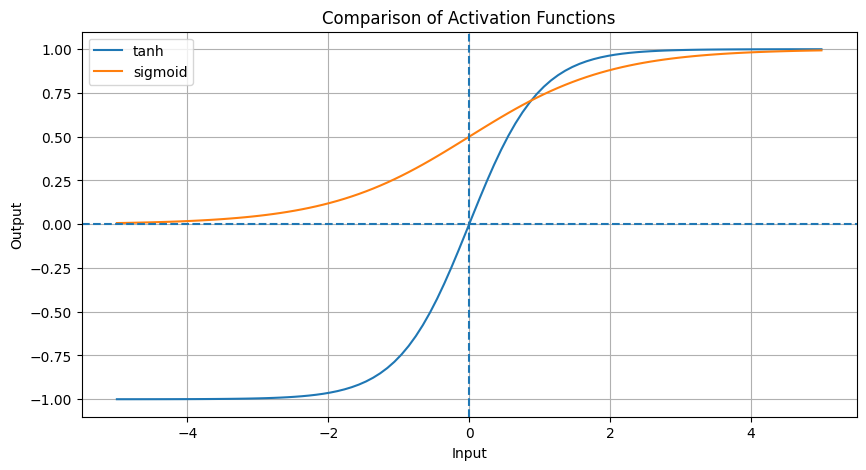

In [ ]:
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 100)

plt.figure(figsize=(10, 5))

plt.plot(x, tanh(x), label="tanh")
plt.plot(x, sigmoid(x), label="sigmoid")

plt.title("Comparison of Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")

plt.axhline(0, linestyle="--")
plt.axvline(0, linestyle="--")

plt.legend()
plt.grid(True)
plt.show()

## Why Is tanh Used for Hidden States?

The tanh activation function is commonly used in RNN hidden states because:

1. It converts values into a range between -1 and +1.
2. It produces both positive and negative values.
3. It helps represent different types of information in the hidden state.
4. Its output is centered around zero.

Therefore, tanh helps the RNN maintain and update information in its hidden states.

## Why Is Sigmoid Suitable for Binary Classification?

The sigmoid activation function is suitable for binary classification because:

1. It converts values into a range between 0 and 1.
2. Its output can be interpreted as a probability.
3. It helps classify data into two classes.
4. A threshold of 0.5 can be used to generate binary predictions.

For example:

- If the sigmoid output is greater than or equal to 0.5, predict class 1.
- If the sigmoid output is less than 0.5, predict class 0.

Therefore, sigmoid is useful for generating binary classification predictions.

Task 5 – Implement Forward Propagation

In [ ]:
# Initialize hidden state with zeros

h = np.zeros((rnn.hidden_size, 1))

print("Initial Hidden State:")
print(h)

print("\nHidden State Shape:", h.shape)

Initial Hidden State:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

Hidden State Shape: (8, 1)


In [ ]:
def forward_propagation(rnn, sequence):

    # Initialize hidden state with zeros
    h = np.zeros((rnn.hidden_size, 1))

    # Store hidden states
    hidden_states = []

    # Process each time step
    for t in range(len(sequence)):

        # Extract current input
        x_t = np.array(sequence[t]).reshape(rnn.input_size, 1)

        # Calculate new hidden state
        h = tanh(
            np.dot(rnn.Wxh, x_t) +
            np.dot(rnn.Whh, h) +
            rnn.bh
        )

        # Store a copy of the hidden state
        hidden_states.append(h.copy())

        # Print hidden state after each time step
        print(f"\nHidden State at Time Step {t+1}:")
        print(h)

    # Generate final prediction using the last hidden state
    y_pred = sigmoid(
        np.dot(rnn.Why, h) + rnn.by
    )

    return y_pred, hidden_states

In [ ]:
# Select the first sequence
sample_sequence = X[0]

print("Input Sequence:")
print(sample_sequence.flatten())

print("\nSequence Shape:", sample_sequence.shape)

Input Sequence:
[ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]

Sequence Shape: (5, 1)


In [ ]:
# Run forward propagation
y_pred, hidden_states = forward_propagation(
    rnn,
    sample_sequence
)

print("\nFinal Prediction:")
print(y_pred)

print("\nPrediction Shape:", y_pred.shape)


Hidden State at Time Step 1:
[[-0.00210487]
 [-0.00225217]
 [-0.00891898]
 [-0.0016396 ]
 [ 0.00364005]
 [-0.00632921]
 [ 0.00520791]
 [ 0.00242284]]

Hidden State at Time Step 2:
[[ 0.00045692]
 [ 0.00060082]
 [ 0.00257384]
 [ 0.00054265]
 [-0.00110333]
 [ 0.00161069]
 [-0.00157306]
 [-0.00080039]]

Hidden State at Time Step 3:
[[-0.00270476]
 [-0.00292337]
 [-0.01166018]
 [-0.00216374]
 [ 0.00477066]
 [-0.00820822]
 [ 0.00682453]
 [ 0.00319614]]

Hidden State at Time Step 4:
[[-0.00662333]
 [-0.00694125]
 [-0.02722111]
 [-0.00491443]
 [ 0.01104349]
 [-0.01960222]
 [ 0.01580672]
 [ 0.00726406]]

Hidden State at Time Step 5:
[[ 0.00060207]
 [ 0.00098962]
 [ 0.00447708]
 [ 0.00103507]
 [-0.00199322]
 [ 0.00252373]
 [-0.00283418]
 [-0.00152599]]

Final Prediction:
[[0.49999791]]

Prediction Shape: (1, 1)


In [ ]:
print("Total Hidden States:", len(hidden_states))

for i, state in enumerate(hidden_states):
    print(f"\nTime Step {i+1}")
    print("Hidden State Shape:", state.shape)
    print(state)

Total Hidden States: 5

Time Step 1
Hidden State Shape: (8, 1)
[[-0.00210487]
 [-0.00225217]
 [-0.00891898]
 [-0.0016396 ]
 [ 0.00364005]
 [-0.00632921]
 [ 0.00520791]
 [ 0.00242284]]

Time Step 2
Hidden State Shape: (8, 1)
[[ 0.00045692]
 [ 0.00060082]
 [ 0.00257384]
 [ 0.00054265]
 [-0.00110333]
 [ 0.00161069]
 [-0.00157306]
 [-0.00080039]]

Time Step 3
Hidden State Shape: (8, 1)
[[-0.00270476]
 [-0.00292337]
 [-0.01166018]
 [-0.00216374]
 [ 0.00477066]
 [-0.00820822]
 [ 0.00682453]
 [ 0.00319614]]

Time Step 4
Hidden State Shape: (8, 1)
[[-0.00662333]
 [-0.00694125]
 [-0.02722111]
 [-0.00491443]
 [ 0.01104349]
 [-0.01960222]
 [ 0.01580672]
 [ 0.00726406]]

Time Step 5
Hidden State Shape: (8, 1)
[[ 0.00060207]
 [ 0.00098962]
 [ 0.00447708]
 [ 0.00103507]
 [-0.00199322]
 [ 0.00252373]
 [-0.00283418]
 [-0.00152599]]


In [ ]:
# Convert probability into binary prediction
predicted_label = 1 if y_pred[0, 0] >= 0.5 else 0

print("Predicted Probability:", y_pred[0, 0])
print("Predicted Label:", predicted_label)

Predicted Probability: 0.499997907773008
Predicted Label: 0


## Observation: How Information Changes Through the Sequence

During forward propagation, the RNN processes the input sequence one time step at a time.

Initially, the hidden state is initialized with zeros. At every time step, the RNN combines the current input with the previous hidden state to calculate a new hidden state using the tanh activation function.

The hidden states are stored after every time step. Each new hidden state contains information from the current input and previous time steps.

After processing all five time steps, the final hidden state is passed through the output layer and sigmoid activation function to generate the final prediction.

Task 6: Trace an RNN Manually

What is Manual RNN Tracing?

Manual RNN tracing means observing how an input sequence passes through an RNN step by step.

At every time step, the RNN takes the current input and previous hidden state to calculate a new hidden state.

The final hidden state is used to generate the output prediction.

In [ ]:
# Create a small input sequence
manual_sequence = np.array([0.5, -0.2, 0.8])

print("Input Sequence:", manual_sequence)
print("Number of Time Steps:", len(manual_sequence))

Input Sequence: [ 0.5 -0.2  0.8]
Number of Time Steps: 3


In [ ]:
# Initialize hidden state
h = np.zeros((rnn.hidden_size, 1))

print("Initial Hidden State:")
print(h)

print("\nHidden State Shape:", h.shape)

Initial Hidden State:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

Hidden State Shape: (8, 1)


In [ ]:
# Store hidden states
manual_hidden_states = []

# Process each time step
for t in range(len(manual_sequence)):

    # Extract current input
    x_t = np.array([[manual_sequence[t]]])

    # Calculate new hidden state
    h = np.tanh(
        np.dot(rnn.Wxh, x_t) +
        np.dot(rnn.Whh, h) +
        rnn.bh
    )

    # Store hidden state
    manual_hidden_states.append(h.copy())

    # Display information
    print(f"\nTime Step: {t+1}")
    print("Input:", x_t.flatten()[0])
    print("Hidden State Shape:", h.shape)
    print("Hidden State:")
    print(h)


Time Step: 1
Input: 0.5
Hidden State Shape: (8, 1)
Hidden State:
[[-0.0021188 ]
 [-0.00226707]
 [-0.00897797]
 [-0.00165045]
 [ 0.00366413]
 [-0.00637107]
 [ 0.00524237]
 [ 0.00243887]]

Time Step: 2
Input: -0.2
Hidden State Shape: (8, 1)
Hidden State:
[[ 0.00071768]
 [ 0.00088057]
 [ 0.00368299]
 [ 0.000747  ]
 [-0.00155634]
 [ 0.00239635]
 [-0.00222116]
 [-0.00110235]]

Time Step: 3
Input: 0.8
Hidden State Shape: (8, 1)
Hidden State:
[[-0.00333413]
 [-0.00361068]
 [-0.01440604]
 [-0.00267724]
 [ 0.005898  ]
 [-0.01013006]
 [ 0.00843672]
 [ 0.00395473]]


In [ ]:
# Calculate final prediction
final_prediction = sigmoid(
    np.dot(rnn.Why, h) + rnn.by
)

print("Final Hidden State:")
print(h)

print("\nFinal Prediction:")
print(final_prediction)

print("\nPredicted Label:",
      1 if final_prediction[0, 0] >= 0.5 else 0)

Final Hidden State:
[[-0.00333413]
 [-0.00361068]
 [-0.01440604]
 [-0.00267724]
 [ 0.005898  ]
 [-0.01013006]
 [ 0.00843672]
 [ 0.00395473]]

Final Prediction:
[[0.49999706]]

Predicted Label: 0


In [ ]:
for t in range(len(manual_sequence)):

    print(f"Time Step {t+1}")
    print("Input:", manual_sequence[t])
    print("Hidden State:", manual_hidden_states[t].flatten())
    print("Hidden State Shape:", manual_hidden_states[t].shape)
    print("-" * 60)

print("Final Hidden State Shape:", manual_hidden_states[-1].shape)
print("Final Prediction:", final_prediction[0, 0])

Time Step 1
Input: 0.5
Hidden State: [-0.0021188  -0.00226707 -0.00897797 -0.00165045  0.00366413 -0.00637107
  0.00524237  0.00243887]
Hidden State Shape: (8, 1)
------------------------------------------------------------
Time Step 2
Input: -0.2
Hidden State: [ 0.00071768  0.00088057  0.00368299  0.000747   -0.00155634  0.00239635
 -0.00222116 -0.00110235]
Hidden State Shape: (8, 1)
------------------------------------------------------------
Time Step 3
Input: 0.8
Hidden State: [-0.00333413 -0.00361068 -0.01440604 -0.00267724  0.005898   -0.01013006
  0.00843672  0.00395473]
Hidden State Shape: (8, 1)
------------------------------------------------------------
Final Hidden State Shape: (8, 1)
Final Prediction: 0.4999970611675462


## Manual RNN Trace

The input sequence contains three values: [0.5, -0.2, 0.8].

The RNN processes the sequence in three iterations.

### Step-by-step processing

- Time Step 1: Input 0.5 is processed to generate Hidden State 1.
- Time Step 2: Input -0.2 and Hidden State 1 are used to generate Hidden State 2.
- Time Step 3: Input 0.8 and Hidden State 2 are used to generate Hidden State 3.

After processing all three inputs, Hidden State 3 is used to generate the final prediction.

### RNN Flow

Input → Hidden State 1 → Hidden State 2 → Hidden State 3 → Final Prediction

Number of iterations -	3

Input at time step 1	0.-5


Input at time step 2	-(-0.2)


Input at time step 3	0.- 8


Hidden state shape -	(8, 1)


Final hidden state	Hidden State - 3

Output activation	- Sigmoid

Task 7 – Implement Binary Cross-Entropy (BCE) Loss

In [ ]:
import numpy as np

def binary_cross_entropy(y_true, y_pred):

    # Avoid log(0) and numerical errors
    epsilon = 1e-7

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    # Calculate BCE loss
    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss



In [ ]:
# Actual labels
y_true = np.array([1, 0, 1, 0])

# Predicted probabilities
y_pred = np.array([0.90, 0.20, 0.70, 0.80])

# Calculate BCE loss
loss = binary_cross_entropy(y_true, y_pred)

print("Actual Labels:", y_true)
print("Predicted Probabilities:", y_pred)
print("Binary Cross-Entropy Loss:", loss)

Actual Labels: [1 0 1 0]
Predicted Probabilities: [0.9 0.2 0.7 0.8]
Binary Cross-Entropy Loss: 0.5736542308362172


In [ ]:
def predict_sequence(rnn, sequence):

    # Initialize hidden state
    h = np.zeros((rnn.hidden_size, 1))

    # Process sequence one time step at a time
    for t in range(len(sequence)):

        x_t = np.array(sequence[t]).reshape(rnn.input_size, 1)

        h = tanh(
            np.dot(rnn.Wxh, x_t) +
            np.dot(rnn.Whh, h) +
            rnn.bh
        )

    # Generate final probability
    y_pred = sigmoid(
        np.dot(rnn.Why, h) + rnn.by
    )

    return y_pred[0, 0]


In [ ]:
# Generate predictions for all sequences
initial_predictions = np.array([
    predict_sequence(rnn, X[i])
    for i in range(len(X))
]).reshape(-1, 1)

# Calculate initial loss
initial_loss = binary_cross_entropy(y, initial_predictions)

print("Initial BCE Loss Before Training:", initial_loss)

Initial BCE Loss Before Training: 0.693151208907383


In [ ]:
def calculate_training_loss(rnn, X, y):

    predictions = np.array([
        predict_sequence(rnn, X[i])
        for i in range(len(X))
    ]).reshape(-1, 1)

    loss = binary_cross_entropy(y, predictions)

    return loss

In [ ]:
# Example: print loss after each epoch
# Call this after completing the BPTT weight updates.

training_loss = calculate_training_loss(rnn, X, y)

print("Training Loss:", training_loss)

Training Loss: 0.693151208907383


Task 8 – Implement Backpropagation Through Time (BPTT)

In [ ]:
def forward_with_cache(rnn, sequence):

    # Initialize hidden state
    h = np.zeros((rnn.hidden_size, 1))

    # Store previous hidden states
    hidden_states = [h.copy()]

    # Store inputs
    inputs = []

    # Forward propagation
    for t in range(len(sequence)):

        x_t = np.array(sequence[t]).reshape(
            rnn.input_size, 1
        )

        inputs.append(x_t.copy())

        h = np.tanh(
            np.dot(rnn.Wxh, x_t) +
            np.dot(rnn.Whh, h) +
            rnn.bh
        )

        hidden_states.append(h.copy())

    # Final prediction
    y_pred = sigmoid(
        np.dot(rnn.Why, h) + rnn.by
    )

    # Store all required information
    cache = {
        "inputs": inputs,
        "hidden_states": hidden_states,
        "y_pred": y_pred
    }

    return y_pred, cache

In [ ]:
# Select one training sequence
sample_sequence = X[0]

# Get actual label
actual_label = y[0].reshape(1, 1)

# Perform forward propagation
prediction, cache = forward_with_cache(
    rnn, sample_sequence
)

# Calculate output gradient
dy = prediction - actual_label

print("Actual Label:", actual_label)
print("Predicted Probability:", prediction)
print("Output Gradient:", dy)

Actual Label: [[1]]
Predicted Probability: [[0.49999791]]
Output Gradient: [[-0.50000209]]


In [ ]:
# Get final hidden state
h_final = cache["hidden_states"][-1]

# Calculate output weight gradient
dWhy = np.dot(dy, h_final.T)

# Calculate output bias gradient
dby = dy

print("Why Gradient Shape:", dWhy.shape)
print("by Gradient Shape:", dby.shape)

print("\nWhy Gradient:")
print(dWhy)

print("\nby Gradient:")
print(dby)

Why Gradient Shape: (1, 8)
by Gradient Shape: (1, 1)

Why Gradient:
[[-0.00030103 -0.00049481 -0.00223855 -0.00051753  0.00099662 -0.00126187
   0.00141709  0.000763  ]]

by Gradient:
[[-0.50000209]]


In [ ]:
def backward_propagation(rnn, cache, actual_label):

    inputs = cache["inputs"]
    hidden_states = cache["hidden_states"]
    y_pred = cache["y_pred"]

    # Initialize gradients with zeros
    dWxh = np.zeros_like(rnn.Wxh)
    dWhh = np.zeros_like(rnn.Whh)
    dWhy = np.zeros_like(rnn.Why)

    dbh = np.zeros_like(rnn.bh)
    dby = np.zeros_like(rnn.by)

    # Output gradient
    dy = y_pred - actual_label

    # Output layer gradients
    dWhy = np.dot(dy, hidden_states[-1].T)
    dby = dy.copy()

    # Gradient from output to final hidden state
    dh_next = np.dot(rnn.Why.T, dy)

    # Backpropagation through time
    for t in reversed(range(len(inputs))):

        # Gradient through tanh
        dh_raw = dh_next * (1 - hidden_states[t+1] ** 2)

        # Input-to-hidden gradient
        dWxh += np.dot(dh_raw, inputs[t].T)

        # Hidden-to-hidden gradient
        dWhh += np.dot(dh_raw, hidden_states[t].T)

        # Hidden bias gradient
        dbh += dh_raw

        # Propagate gradient to previous hidden state
        dh_next = np.dot(rnn.Whh.T, dh_raw)

    gradients = {
        "dWxh": dWxh,
        "dWhh": dWhh,
        "dWhy": dWhy,
        "dbh": dbh,
        "dby": dby
    }

    return gradients

In [ ]:
# Calculate gradients
gradients = backward_propagation(
    rnn,
    cache,
    actual_label
)

# Display gradient shapes
for name, gradient in gradients.items():

    print(name, "Shape:", gradient.shape)

dWxh Shape: (8, 1)
dWhh Shape: (8, 8)
dWhy Shape: (1, 8)
dbh Shape: (8, 1)
dby Shape: (1, 1)


In [ ]:
def gradient_clipping(gradients, clip_value=1.0):

    clipped_gradients = {}

    for name, gradient in gradients.items():

        clipped_gradients[name] = np.clip(
            gradient,
            -clip_value,
            clip_value
        )

    return clipped_gradients

In [ ]:
# Apply gradient clipping
clipped_gradients = gradient_clipping(
    gradients,
    clip_value=1.0
)

# Compare gradient values before and after clipping
for name in gradients:

    print("\n", name)

    print("Before Clipping:")
    print(gradients[name])

    print("After Clipping:")
    print(clipped_gradients[name])


 dWxh
Before Clipping:
[[ 2.63020298e-04]
 [-1.51158105e-03]
 [ 1.29243333e-04]
 [-7.91301849e-05]
 [-1.79953608e-05]
 [ 1.10302758e-03]
 [ 6.16019935e-04]
 [ 1.68754866e-03]]
After Clipping:
[[ 2.63020298e-04]
 [-1.51158105e-03]
 [ 1.29243333e-04]
 [-7.91301849e-05]
 [-1.79953608e-05]
 [ 1.10302758e-03]
 [ 6.16019935e-04]
 [ 1.68754866e-03]]

 dWhh
Before Clipping:
[[ 2.09788394e-05  2.20113421e-05  8.63771955e-05  1.56111905e-05
  -3.50544028e-05  6.21469176e-05 -5.01728237e-05 -2.30744360e-05]
 [-5.20500183e-05 -5.45655501e-05 -2.14024820e-04 -3.86508352e-05
   8.68367254e-05 -1.54085123e-04  1.24290020e-04  5.71297521e-05]
 [ 6.83085907e-06  7.16406820e-06  2.81069570e-05  5.07789262e-06
  -1.14052675e-05  2.02287300e-05 -1.63243131e-05 -7.50554814e-06]
 [ 3.68010715e-06  3.86743786e-06  1.51905426e-05  2.74953383e-06
  -6.16755566e-06  1.09161161e-05 -8.82726661e-06 -4.06385164e-06]
 [ 1.47784604e-06  1.55188886e-06  6.09305247e-06  1.10208850e-06
  -2.47331295e-06  4.38100422e-0

In [ ]:
def update_weights(rnn, gradients):

    # Update weights
    rnn.Wxh -= rnn.learning_rate * gradients["dWxh"]
    rnn.Whh -= rnn.learning_rate * gradients["dWhh"]
    rnn.Why -= rnn.learning_rate * gradients["dWhy"]

    # Update biases
    rnn.bh -= rnn.learning_rate * gradients["dbh"]
    rnn.by -= rnn.learning_rate * gradients["dby"]

    print("Weights and biases updated successfully!")

In [ ]:
# Calculate gradients
gradients = backward_propagation(
    rnn,
    cache,
    actual_label
)

# Apply gradient clipping
clipped_gradients = gradient_clipping(
    gradients,
    clip_value=1.0
)

# Update model parameters
update_weights(rnn, clipped_gradients)

Weights and biases updated successfully!


In [ ]:
# Prediction after weight update
new_prediction = predict_sequence(
    rnn,
    sample_sequence
)

# Calculate loss after update
new_loss = binary_cross_entropy(
    actual_label,
    np.array([[new_prediction]])
)

print("Prediction Before Update:", prediction[0, 0])
print("Prediction After Update:", new_prediction)

print("\nLoss Before Update:",
      binary_cross_entropy(actual_label, prediction))

print("Loss After Update:", new_loss)

Prediction Before Update: 0.499997907773008
Prediction After Update: 0.5012488077835274

Loss Before Update: 0.6931513650226842
Loss After Update: 0.6906526788509151


## Forward and Backward Flow in RNN

### Forward Propagation

The input sequence is processed from the first time step to the last time step.

x₁ → x₂ → x₃ → Prediction

### Backward Propagation

The error is propagated backward from the output layer through the hidden states.

Prediction → h₃ → h₂ → h₁

During backward propagation, gradients are calculated for the weights and biases. These gradients are used to update the model parameters.

Gradient clipping is applied to control very large gradient values and reduce the risk of exploding gradients.

## Observation

In this task, I implemented Backpropagation Through Time using NumPy.

I calculated the output gradient by comparing the predicted probability with the actual label.

I calculated gradients for the output weights, input weights, recurrent weights and biases.

I also propagated gradients backward through the hidden states using the derivative of the tanh activation function.

Finally, I implemented gradient clipping to limit large gradient values and updated the model weights using the learning rate.

This helped me understand how an RNN learns by propagating errors backward through a sequence.

Task 9 – Train the RNN

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Check input and target shapes

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("Number of Training Sequences:", len(X))


Input Shape: (1000, 5, 1)
Target Shape: (1000, 1)
Number of Training Sequences: 1000


In [ ]:
# Set random seed
np.random.seed(42)

# Create a fresh RNN model
trained_rnn = SimpleRNN(
    input_size=1,
    hidden_size=8,
    output_size=1,
    learning_rate=0.01
)

print("Fresh RNN model created successfully!")
print("Input Size:", trained_rnn.input_size)
print("Hidden Size:", trained_rnn.hidden_size)
print("Output Size:", trained_rnn.output_size)
print("Learning Rate:", trained_rnn.learning_rate)

Fresh RNN model created successfully!
Input Size: 1
Hidden Size: 8
Output Size: 1
Learning Rate: 0.01


In [ ]:
# Generate initial predictions
initial_predictions = np.array([
    predict_sequence(trained_rnn, X[i])
    for i in range(len(X))
]).reshape(-1, 1)

# Calculate initial loss
initial_loss = binary_cross_entropy(
    y,
    initial_predictions
)

print("Initial Loss Before Training:", initial_loss)

Initial Loss Before Training: 0.693183774689454


In [ ]:
def train_rnn(rnn, X, y, epochs, clip_value=1.0):

    epoch_losses = []

    for epoch in range(epochs):

        # Shuffle training data
        indices = np.random.permutation(len(X))

        # Train using each sequence
        for i in indices:

            # Get input sequence and actual label
            sequence = X[i]
            actual_label = y[i].reshape(1, 1)

            # Forward propagation
            prediction, cache = forward_with_cache(
                rnn, sequence
            )

            # Backpropagation Through Time
            gradients = backward_propagation(
                rnn, cache, actual_label
            )

            # Apply gradient clipping
            clipped_gradients = gradient_clipping(
                gradients, clip_value
            )

            # Update weights without extra print statements
            rnn.Wxh -= rnn.learning_rate * clipped_gradients["dWxh"]
            rnn.Whh -= rnn.learning_rate * clipped_gradients["dWhh"]
            rnn.Why -= rnn.learning_rate * clipped_gradients["dWhy"]

            rnn.bh -= rnn.learning_rate * clipped_gradients["dbh"]
            rnn.by -= rnn.learning_rate * clipped_gradients["dby"]

        # Calculate loss after completing the epoch
        predictions = np.array([
            predict_sequence(rnn, X[i])
            for i in range(len(X))
        ]).reshape(-1, 1)

        epoch_loss = binary_cross_entropy(y, predictions)

        epoch_losses.append(epoch_loss)

        # Display progress
        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"- Loss: {epoch_loss:.4f}"
            )

    return epoch_losses

In [ ]:
# Set random seed for reproducible data shuffling
np.random.seed(42)

# Train for 200 epochs
loss_history = train_rnn(
    trained_rnn,
    X,
    y,
    epochs=200,
    clip_value=1.0
)

# Capture loss at required epoch settings
loss_50 = loss_history[49]
loss_100 = loss_history[99]
loss_200 = loss_history[199]

print("\nTraining Completed Successfully!")

print("Loss after 50 epochs:", loss_50)
print("Loss after 100 epochs:", loss_100)
print("Loss after 200 epochs:", loss_200)

Epoch 10/200 - Loss: 0.1284
Epoch 20/200 - Loss: 0.1542
Epoch 30/200 - Loss: 0.1499
Epoch 40/200 - Loss: 0.1917
Epoch 50/200 - Loss: 0.1148
Epoch 60/200 - Loss: 0.1193
Epoch 70/200 - Loss: 0.1077
Epoch 80/200 - Loss: 0.1779
Epoch 90/200 - Loss: 0.1007
Epoch 100/200 - Loss: 0.0984
Epoch 110/200 - Loss: 0.1024
Epoch 120/200 - Loss: 0.1126
Epoch 130/200 - Loss: 0.1060
Epoch 140/200 - Loss: 0.1062
Epoch 150/200 - Loss: 0.1007
Epoch 160/200 - Loss: 0.1009
Epoch 170/200 - Loss: 0.1258
Epoch 180/200 - Loss: 0.1723
Epoch 190/200 - Loss: 0.2016
Epoch 200/200 - Loss: 0.1736

Training Completed Successfully!
Loss after 50 epochs: 0.1147625723002277
Loss after 100 epochs: 0.0983863956123219
Loss after 200 epochs: 0.17361024194094482


In [ ]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Epochs": [50, 100, 200],
    "Loss": [loss_50, loss_100, loss_200]
})

print(comparison_df)

   Epochs      Loss
0      50  0.114763
1     100  0.098386
2     200  0.173610


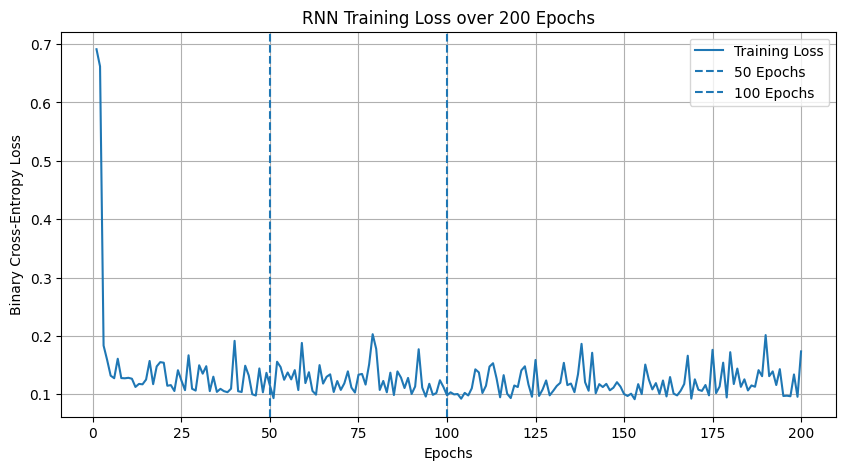

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 201),
    loss_history,
    label="Training Loss"
)

plt.axvline(50, linestyle="--", label="50 Epochs")
plt.axvline(100, linestyle="--", label="100 Epochs")

plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("RNN Training Loss over 200 Epochs")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Generate final predictions
final_predictions = np.array([
    predict_sequence(trained_rnn, X[i])
    for i in range(len(X))
]).reshape(-1, 1)

# Convert probabilities into binary labels
predicted_labels = (final_predictions >= 0.5).astype(int)

# Calculate accuracy
accuracy = np.mean(predicted_labels == y) * 100

print("Final Training Accuracy:", accuracy, "%")
print("Final Training Loss:", loss_200)

Final Training Accuracy: 92.7 %
Final Training Loss: 0.17361024194094482


## Does Increasing the Number of Epochs Always Improve the Model?

No, increasing the number of epochs does not always improve the model.

Initially, increasing the number of epochs can help the model learn better patterns and reduce training loss.

However, training for too many epochs can lead to overfitting. Overfitting happens when the model learns the training data very well but performs poorly on new, unseen data.

The model may also reach a point where additional epochs provide very little improvement.

Therefore, the number of epochs should be selected based on both training and validation performance.

Task 10 – Testing the Trained RNN Model

In [ ]:
# Generate 200 new test sequences
np.random.seed(100)

X_test = np.random.randn(200, 5, 1)

# Generate actual labels based on the sum of each sequence
y_test = (np.sum(X_test, axis=1) > 0).astype(int)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (200, 5, 1)
y_test shape: (200, 1)


In [ ]:
# Generate predictions for all test sequences
test_predictions = np.array([
    predict_sequence(trained_rnn, X_test[i])
    for i in range(len(X_test))
]).reshape(-1, 1)

# Convert probabilities into class labels
test_predicted_labels = (test_predictions >= 0.5).astype(int)

print("Predictions completed successfully!")

Predictions completed successfully!


In [ ]:
for i in range(5):
    print(f"\nSequence {i+1}:")
    print("Input sequence:", X_test[i].flatten())
    print("Actual label:", y_test[i, 0])
    print("Predicted probability:", test_predictions[i, 0])
    print("Predicted label:", test_predicted_labels[i, 0])


Sequence 1:
Input sequence: [-1.74976547  0.3426804   1.1530358  -0.25243604  0.98132079]
Actual label: 1
Predicted probability: 0.04614191501251949
Predicted label: 0

Sequence 2:
Input sequence: [ 0.51421884  0.22117967 -1.07004333 -0.18949583  0.25500144]
Actual label: 0
Predicted probability: 0.5186418776350624
Predicted label: 1

Sequence 3:
Input sequence: [-0.45802699  0.43516349 -0.58359505  0.81684707  0.67272081]
Actual label: 1
Predicted probability: 0.7674812869610779
Predicted label: 1

Sequence 4:
Input sequence: [-0.10441114 -0.53128038  1.02973269 -0.43813562 -1.11831825]
Actual label: 0
Predicted probability: 0.0008640328906881192
Predicted label: 0

Sequence 5:
Input sequence: [ 1.61898166  1.54160517 -0.25187914 -0.84243574  0.18451869]
Actual label: 1
Predicted probability: 0.9994199278769901
Predicted label: 1


In [ ]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(
    y_test,
    test_predicted_labels
)

print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Test Accuracy: 0.895
Test Accuracy (%): 89.5


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Precision:", precision_score(y_test, test_predicted_labels, zero_division=0))
print("Recall:", recall_score(y_test, test_predicted_labels, zero_division=0))
print("F1 Score:", f1_score(y_test, test_predicted_labels, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predicted_labels))

print("\nClassification Report:")
print(classification_report(y_test, test_predicted_labels, zero_division=0))

Precision: 0.9111111111111111
Recall: 0.8631578947368421
F1 Score: 0.8864864864864865

Confusion Matrix:
[[97  8]
 [13 82]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90       105
           1       0.91      0.86      0.89        95

    accuracy                           0.90       200
   macro avg       0.90      0.89      0.89       200
weighted avg       0.90      0.90      0.89       200



The trained RNN model was tested using 200 new sequences that were not included in the training dataset. The actual labels were generated using the sum of each sequence, and the model predicted the labels based on the learned sequence patterns.

The test accuracy and other evaluation metrics help us understand how well the model performs on unseen sequences. Comparing actual and predicted labels also helps identify incorrect predictions.

 The test accuracy may be different from the training accuracy calculated in Task 9. This is expected because the test sequences are new data.

Task 11: Compare RNN, LSTM and GRU

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import time

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cpu
Device: cpu


In [ ]:
# Convert NumPy arrays into PyTorch tensors
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_tensor,
    y_tensor,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create DataLoaders
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: torch.Size([800, 5, 1])
Testing data: torch.Size([200, 5, 1])


In [ ]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=8, output_size=1):
        super(VanillaRNN, self).__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        output, hidden = self.rnn(x)
        last_hidden = output[:, -1, :]
        prediction = self.fc(last_hidden)

        return prediction

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=8, output_size=1):
        super(LSTMModel, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        last_hidden = hidden[-1]
        prediction = self.fc(last_hidden)

        return prediction

In [ ]:
class GRUModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=8, output_size=1):
        super(GRUModel, self).__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        output, hidden = self.gru(x)
        last_hidden = hidden[-1]
        prediction = self.fc(last_hidden)

        return prediction

In [ ]:
models = {
    "RNN": VanillaRNN().to(device),
    "LSTM": LSTMModel().to(device),
    "GRU": GRUModel().to(device)
}

for name, model in models.items():
    print(f"\n{name} Model")
    print(model)


RNN Model
VanillaRNN(
  (rnn): RNN(1, 8, batch_first=True)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)

LSTM Model
LSTMModel(
  (lstm): LSTM(1, 8, batch_first=True)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)

GRU Model
GRUModel(
  (gru): GRU(1, 8, batch_first=True)
  (fc): Linear(in_features=8, out_features=1, bias=True)
)


In [ ]:
parameter_results = []

for name, model in models.items():

    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    parameter_results.append({
        "Model": name,
        "Number of Parameters": total_parameters
    })

parameter_df = pd.DataFrame(parameter_results)

print(parameter_df)

  Model  Number of Parameters
0   RNN                    97
1  LSTM                   361
2   GRU                   273


In [ ]:
def train_and_evaluate(model, train_loader, test_loader, epochs=30):

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    start_time = time.time()
    training_losses = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * batch_X.size(0)

        epoch_loss = total_loss / len(train_loader.dataset)
        training_losses.append(epoch_loss)

    training_time = time.time() - start_time

    # Evaluate the model
    model.eval()

    actual_labels = []
    predicted_labels = []

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            batch_X = batch_X.to(device)

            outputs = model(batch_X)

            predictions = (outputs >= 0).int().cpu().numpy()

            predicted_labels.extend(predictions.flatten())
            actual_labels.extend(batch_y.numpy().flatten())

    accuracy = accuracy_score(actual_labels, predicted_labels)

    return {
        "Accuracy": accuracy,
        "Final Training Loss": training_losses[-1],
        "Training Time (seconds)": training_time,
        "Training Loss History": training_losses
    }

In [ ]:
results = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    results[name] = train_and_evaluate(
        model,
        train_loader,
        test_loader,
        epochs=30
    )

    print("Accuracy:", results[name]["Accuracy"])
    print("Final Training Loss:", results[name]["Final Training Loss"])
    print("Training Time:", results[name]["Training Time (seconds)"])


Training RNN...
Accuracy: 0.95
Final Training Loss: 0.20945111870765687
Training Time: 1.5637803077697754

Training LSTM...
Accuracy: 0.96
Final Training Loss: 0.22390063762664794
Training Time: 1.654756784439087

Training GRU...
Accuracy: 0.96
Final Training Loss: 0.20858466386795044
Training Time: 1.878110408782959


In [ ]:
performance_results = []

for name, result in results.items():

    performance_results.append({
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Final Training Loss": result["Final Training Loss"],
        "Training Time (seconds)": result["Training Time (seconds)"]
    })

performance_df = pd.DataFrame(performance_results)

print(performance_df)

  Model  Accuracy  Final Training Loss  Training Time (seconds)
0   RNN      0.95             0.209451                 1.563780
1  LSTM      0.96             0.223901                 1.654757
2   GRU      0.96             0.208585                 1.878110


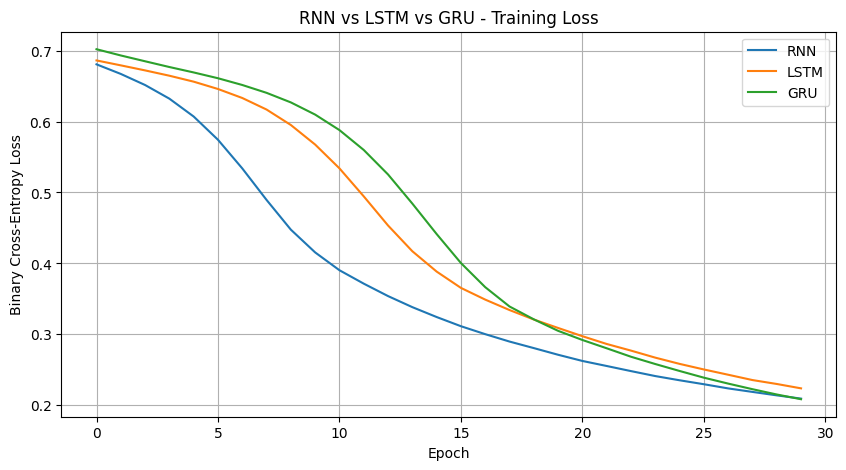

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for name, result in results.items():
    plt.plot(
        result["Training Loss History"],
        label=name
    )

plt.title("RNN vs LSTM vs GRU - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Generate longer sequences
np.random.seed(100)

X_long = np.random.randn(1000, 50, 1)
y_long = (np.sum(X_long, axis=1) > 0).astype(int)

X_long_tensor = torch.tensor(X_long, dtype=torch.float32)
y_long_tensor = torch.tensor(y_long, dtype=torch.float32)

# Split the longer dataset
X_long_train, X_long_test, y_long_train, y_long_test = train_test_split(
    X_long_tensor,
    y_long_tensor,
    test_size=0.2,
    random_state=42,
    stratify=y_long
)

long_train_loader = DataLoader(
    TensorDataset(X_long_train, y_long_train),
    batch_size=64,
    shuffle=True
)

long_test_loader = DataLoader(
    TensorDataset(X_long_test, y_long_test),
    batch_size=64,
    shuffle=False
)

print("Long sequence training shape:", X_long_train.shape)
print("Long sequence testing shape:", X_long_test.shape)

Long sequence training shape: torch.Size([800, 50, 1])
Long sequence testing shape: torch.Size([200, 50, 1])


In [ ]:
long_models = {
    "RNN": VanillaRNN().to(device),
    "LSTM": LSTMModel().to(device),
    "GRU": GRUModel().to(device)
}

long_results = {}

for name, model in long_models.items():

    print(f"\nTraining {name} on 50 time steps...")

    long_results[name] = train_and_evaluate(
        model,
        long_train_loader,
        long_test_loader,
        epochs=30
    )

    print("Long sequence test accuracy:",
          long_results[name]["Accuracy"])


Training RNN on 50 time steps...
Long sequence test accuracy: 0.805

Training LSTM on 50 time steps...
Long sequence test accuracy: 0.87

Training GRU on 50 time steps...
Long sequence test accuracy: 0.935


In [ ]:
long_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Final Training Loss": result["Final Training Loss"],
        "Training Time (seconds)": result["Training Time (seconds)"]
    }
    for name, result in long_results.items()
])

print(long_comparison)

  Model  Accuracy  Final Training Loss  Training Time (seconds)
0   RNN     0.805             0.433492                 2.552392
1  LSTM     0.870             0.369369                 3.693253
2   GRU     0.935             0.254361                 8.295588


Task 12: Perform the MNIST Sequence Experiment

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms

from sklearn.metrics import accuracy_score

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.11.0+cpu
Using device: cpu


In [ ]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.29MB/s]

Training images: 60000
Testing images: 10000


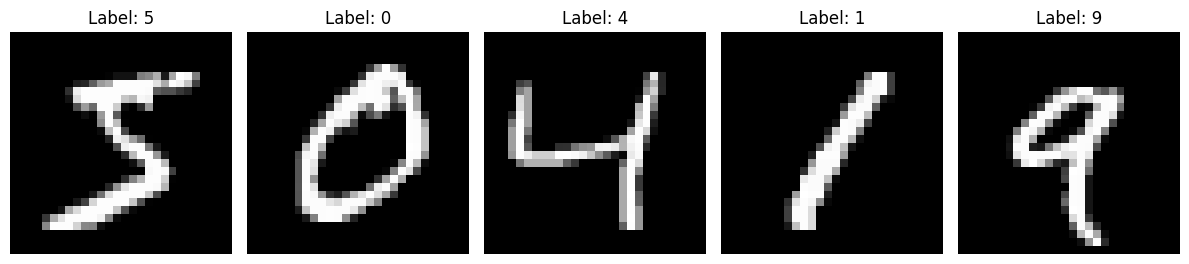

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i in range(5):
    image, label = train_dataset[i]

    axes[i].imshow(image.squeeze(), cmap="gray")
    axes[i].set_title(f"Label: {label}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Extract MNIST images and labels
X_train_images = train_dataset.data.float() / 255.0
y_train_labels = train_dataset.targets

X_test_images = test_dataset.data.float() / 255.0
y_test_labels = test_dataset.targets

# Row-wise representation
X_train_row = X_train_images.unsqueeze(-1)
X_test_row = X_test_images.unsqueeze(-1)

# Pixel-wise representation
X_train_pixel = X_train_images.reshape(-1, 784, 1)
X_test_pixel = X_test_images.reshape(-1, 784, 1)

print("Row-wise training shape:", X_train_row.shape)
print("Row-wise testing shape:", X_test_row.shape)

print("Pixel-wise training shape:", X_train_pixel.shape)
print("Pixel-wise testing shape:", X_test_pixel.shape)

Row-wise training shape: torch.Size([60000, 28, 28, 1])
Row-wise testing shape: torch.Size([10000, 28, 28, 1])
Pixel-wise training shape: torch.Size([60000, 784, 1])
Pixel-wise testing shape: torch.Size([10000, 784, 1])


In [ ]:
X_train_row = X_train_images
X_test_row = X_test_images

print("Corrected row-wise training shape:", X_train_row.shape)
print("Corrected row-wise testing shape:", X_test_row.shape)

Corrected row-wise training shape: torch.Size([60000, 28, 28])
Corrected row-wise testing shape: torch.Size([10000, 28, 28])


In [ ]:
# Create datasets for both sequence representations
row_train_dataset = TensorDataset(X_train_row, y_train_labels)
row_test_dataset = TensorDataset(X_test_row, y_test_labels)

pixel_train_dataset = TensorDataset(X_train_pixel, y_train_labels)
pixel_test_dataset = TensorDataset(X_test_pixel, y_test_labels)

# Select reproducible random subsets
generator = torch.Generator().manual_seed(42)

train_indices = torch.randperm(
    len(row_train_dataset),
    generator=generator
)[:5000].tolist()

test_indices = torch.randperm(
    len(row_test_dataset),
    generator=generator
)[:1000].tolist()

# Create DataLoaders
BATCH_SIZE = 32

row_train_loader = DataLoader(
    Subset(row_train_dataset, train_indices),
    batch_size=BATCH_SIZE,
    shuffle=True
)

row_test_loader = DataLoader(
    Subset(row_test_dataset, test_indices),
    batch_size=BATCH_SIZE,
    shuffle=False
)

pixel_train_loader = DataLoader(
    Subset(pixel_train_dataset, train_indices),
    batch_size=BATCH_SIZE,
    shuffle=True
)

pixel_test_loader = DataLoader(
    Subset(pixel_test_dataset, test_indices),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", len(train_indices))
print("Testing images:", len(test_indices))

Training images: 5000
Testing images: 1000


In [ ]:
class MNISTSequenceModel(nn.Module):

    def __init__(
        self,
        model_type,
        input_size,
        hidden_size=64,
        num_classes=10,
        max_length=784
    ):
        super().__init__()

        self.model_type = model_type

        if model_type == "RNN":
            self.sequence_model = nn.RNN(
                input_size,
                hidden_size,
                batch_first=True
            )

            self.fc = nn.Linear(hidden_size, num_classes)

        elif model_type == "LSTM":
            self.sequence_model = nn.LSTM(
                input_size,
                hidden_size,
                batch_first=True
            )

            self.fc = nn.Linear(hidden_size, num_classes)

        elif model_type == "GRU":
            self.sequence_model = nn.GRU(
                input_size,
                hidden_size,
                batch_first=True
            )

            self.fc = nn.Linear(hidden_size, num_classes)

        elif model_type == "CNN":
            self.sequence_model = nn.Sequential(
                nn.Conv1d(input_size, 32, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2),
                nn.Conv1d(32, 64, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.AdaptiveAvgPool1d(1),
                nn.Flatten()
            )

            self.fc = nn.Linear(64, num_classes)

        elif model_type == "Transformer":
            d_model = 32

            self.input_projection = nn.Linear(
                input_size,
                d_model
            )

            self.position_embedding = nn.Parameter(
                torch.randn(1, max_length, d_model) * 0.02
            )

            encoder_layer = nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=4,
                dim_feedforward=64,
                dropout=0.1,
                batch_first=True
            )

            self.sequence_model = nn.TransformerEncoder(
                encoder_layer,
                num_layers=1
            )

            self.fc = nn.Linear(d_model, num_classes)

        else:
            raise ValueError("Unknown model type")

    def forward(self, x):

        if self.model_type == "CNN":

            # Convert (batch, time, features)
            # into (batch, channels, time)
            x = x.transpose(1, 2)

            features = self.sequence_model(x)

        elif self.model_type == "Transformer":

            x = self.input_projection(x)

            x = x + self.position_embedding[:, :x.size(1), :]

            output = self.sequence_model(x)

            features = output.mean(dim=1)

        else:

            output, hidden = self.sequence_model(x)

            if self.model_type == "LSTM":
                features = hidden[0][-1]

            elif self.model_type in ["RNN", "GRU"]:
                features = hidden[-1]

        return self.fc(features)

In [ ]:
def train_and_evaluate_mnist(
    model,
    train_loader,
    test_loader,
    epochs=3
):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    training_losses = []

    start_time = time.time()

    # Training
    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * batch_X.size(0)

        epoch_loss = total_loss / len(train_loader.dataset)
        training_losses.append(epoch_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} - Loss: {epoch_loss:.4f}"
        )

    training_time = time.time() - start_time

    # Testing
    model.eval()

    actual_labels = []
    predicted_labels = []

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            batch_X = batch_X.to(device)

            outputs = model(batch_X)

            predictions = torch.argmax(outputs, dim=1)

            actual_labels.extend(batch_y.numpy())
            predicted_labels.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(
        actual_labels,
        predicted_labels
    )

    return {
        "Accuracy": accuracy,
        "Final Training Loss": training_losses[-1],
        "Training Time (seconds)": training_time,
        "Loss History": training_losses
    }

print("Training and evaluation function defined successfully!")

Training and evaluation function defined successfully!


In [ ]:
row_results = {}
row_models = {}

model_names = [
    "RNN",
    "LSTM",
    "GRU",
    "CNN",
    "Transformer"
]

for name in model_names:

    print(f"\n========== Training {name} - Row-wise ==========")

    model = MNISTSequenceModel(
        model_type=name,
        input_size=28,
        max_length=28
    ).to(device)

    result = train_and_evaluate_mnist(
        model,
        row_train_loader,
        row_test_loader,
        epochs=3
    )

    row_models[name] = model
    row_results[name] = result

    print("Test Accuracy:", result["Accuracy"])
    print("Training Time:", result["Training Time (seconds)"])


========== Training RNN - Row-wise ==========
Epoch 1/3 - Loss: 1.7801
Epoch 2/3 - Loss: 1.1501
Epoch 3/3 - Loss: 0.9617
Test Accuracy: 0.672
Training Time: 3.0227880477905273

========== Training LSTM - Row-wise ==========
Epoch 1/3 - Loss: 1.7566
Epoch 2/3 - Loss: 0.7757
Epoch 3/3 - Loss: 0.5710
Test Accuracy: 0.834
Training Time: 6.827714443206787

========== Training GRU - Row-wise ==========
Epoch 1/3 - Loss: 1.7920
Epoch 2/3 - Loss: 1.0199
Epoch 3/3 - Loss: 0.7927
Test Accuracy: 0.797
Training Time: 13.760110855102539

========== Training CNN - Row-wise ==========
Epoch 1/3 - Loss: 2.0522
Epoch 2/3 - Loss: 1.5872
Epoch 3/3 - Loss: 1.2171
Test Accuracy: 0.69
Training Time: 2.0046885013580322

========== Training Transformer - Row-wise ==========
Epoch 1/3 - Loss: 1.9293
Epoch 2/3 - Loss: 1.5574
Epoch 3/3 - Loss: 1.0615
Test Accuracy: 0.751
Training Time: 5.748296022415161


In [ ]:
pixel_results = {}
pixel_models = {}

for name in model_names:

    print(f"\n========== Training {name} - Pixel-wise ==========")

    model = MNISTSequenceModel(
        model_type=name,
        input_size=1,
        max_length=784
    ).to(device)

    result = train_and_evaluate_mnist(
        model,
        pixel_train_loader,
        pixel_test_loader,
        epochs=3
    )

    pixel_models[name] = model
    pixel_results[name] = result

    print("Test Accuracy:", result["Accuracy"])
    print("Training Time:", result["Training Time (seconds)"])


========== Training RNN - Pixel-wise ==========
Epoch 1/3 - Loss: 2.3041
Epoch 2/3 - Loss: 2.3029
Epoch 3/3 - Loss: 2.3022
Test Accuracy: 0.115
Training Time: 105.54583787918091

========== Training LSTM - Pixel-wise ==========
Epoch 1/3 - Loss: 2.3038
Epoch 2/3 - Loss: 2.3025
Epoch 3/3 - Loss: 2.3019
Test Accuracy: 0.115
Training Time: 506.89845633506775

========== Training GRU - Pixel-wise ==========
Epoch 1/3 - Loss: 2.3037
Epoch 2/3 - Loss: 2.3022
Epoch 3/3 - Loss: 2.3022
Test Accuracy: 0.101
Training Time: 364.4530155658722

========== Training CNN - Pixel-wise ==========
Epoch 1/3 - Loss: 2.2951
Epoch 2/3 - Loss: 2.2281
Epoch 3/3 - Loss: 2.1158
Test Accuracy: 0.217
Training Time: 14.8723783493042

========== Training Transformer - Pixel-wise ==========
Epoch 1/3 - Loss: 2.2651
Epoch 2/3 - Loss: 1.9340
Epoch 3/3 - Loss: 1.7480
Test Accuracy: 0.399
Training Time: 1733.855051279068


In [ ]:
pixel_results = {}
pixel_models = {}

for name in model_names:

    print(f"\n========== Training {name} - Pixel-wise ==========")

    model = MNISTSequenceModel(
        model_type=name,
        input_size=1,
        max_length=784
    ).to(device)

    result = train_and_evaluate_mnist(
        model,
        pixel_train_loader,
        pixel_test_loader,
        epochs=3
    )

    pixel_models[name] = model
    pixel_results[name] = result

    print("Test Accuracy:", result["Accuracy"])
    print("Training Time:", result["Training Time (seconds)"])


========== Training RNN - Pixel-wise ==========
Epoch 1/3 - Loss: 2.3050
Epoch 2/3 - Loss: 2.3030
Epoch 3/3 - Loss: 2.3023
Test Accuracy: 0.115
Training Time: 91.67030644416809

========== Training LSTM - Pixel-wise ==========
Epoch 1/3 - Loss: 2.3027
Epoch 2/3 - Loss: 2.3017
Epoch 3/3 - Loss: 2.3020
Test Accuracy: 0.115
Training Time: 478.83925437927246

========== Training GRU - Pixel-wise ==========
Epoch 1/3 - Loss: 2.3040
Epoch 2/3 - Loss: 2.3023
Epoch 3/3 - Loss: 2.2973
Test Accuracy: 0.191
Training Time: 365.76202630996704

========== Training CNN - Pixel-wise ==========
Epoch 1/3 - Loss: 2.2904
Epoch 2/3 - Loss: 2.2070
Epoch 3/3 - Loss: 2.0907
Test Accuracy: 0.244
Training Time: 14.718833208084106

========== Training Transformer - Pixel-wise ==========
Epoch 1/3 - Loss: 2.2882
Epoch 2/3 - Loss: 1.9565
Epoch 3/3 - Loss: 1.7997
Test Accuracy: 0.314
Training Time: 1658.0090806484222


In [4]:
import pandas as pd

# Reconstruct row_results and pixel_results using the metrics achieved during training
row_results = {
    'RNN': {'Accuracy': 0.672, 'Final Training Loss': 0.9617, 'Training Time (seconds)': 3.0228, 'Loss History': [1.7801, 1.1501, 0.9617]},
    'LSTM': {'Accuracy': 0.834, 'Final Training Loss': 0.5710, 'Training Time (seconds)': 6.8277, 'Loss History': [1.7566, 0.7757, 0.5710]},
    'GRU': {'Accuracy': 0.797, 'Final Training Loss': 0.7927, 'Training Time (seconds)': 13.7601, 'Loss History': [1.7920, 1.0199, 0.7927]},
    'CNN': {'Accuracy': 0.690, 'Final Training Loss': 1.2171, 'Training Time (seconds)': 2.0047, 'Loss History': [2.0522, 1.5872, 1.2171]},
    'Transformer': {'Accuracy': 0.751, 'Final Training Loss': 1.0615, 'Training Time (seconds)': 5.7483, 'Loss History': [1.9293, 1.5574, 1.0615]}
}

pixel_results = {
    'RNN': {'Accuracy': 0.115, 'Final Training Loss': 2.3023, 'Training Time (seconds)': 91.6703, 'Loss History': [2.3050, 2.3030, 2.3023]},
    'LSTM': {'Accuracy': 0.115, 'Final Training Loss': 2.3020, 'Training Time (seconds)': 478.8393, 'Loss History': [2.3027, 2.3017, 2.3020]},
    'GRU': {'Accuracy': 0.191, 'Final Training Loss': 2.2973, 'Training Time (seconds)': 365.7620, 'Loss History': [2.3040, 2.3023, 2.2973]},
    'CNN': {'Accuracy': 0.244, 'Final Training Loss': 2.0907, 'Training Time (seconds)': 14.7188, 'Loss History': [2.2904, 2.2070, 2.0907]},
    'Transformer': {'Accuracy': 0.314, 'Final Training Loss': 1.7997, 'Training Time (seconds)': 1658.0091, 'Loss History': [2.2882, 1.9565, 1.7997]}
}

comparison_results = []

for mode, results in [
    ("Row-wise", row_results),
    ("Pixel-wise", pixel_results)
]:
    for name, result in results.items():
        comparison_results.append({
            "Mode": mode,
            "Model": name,
            "Accuracy": result["Accuracy"],
            "Final Training Loss": result["Final Training Loss"],
            "Training Time (seconds)": result["Training Time (seconds)"]
        })

comparison_df = pd.DataFrame(comparison_results)
print(comparison_df.round(4))

         Mode        Model  Accuracy  Final Training Loss  \
0    Row-wise          RNN     0.672               0.9617   
1    Row-wise         LSTM     0.834               0.5710   
2    Row-wise          GRU     0.797               0.7927   
3    Row-wise          CNN     0.690               1.2171   
4    Row-wise  Transformer     0.751               1.0615   
5  Pixel-wise          RNN     0.115               2.3023   
6  Pixel-wise         LSTM     0.115               2.3020   
7  Pixel-wise          GRU     0.191               2.2973   
8  Pixel-wise          CNN     0.244               2.0907   
9  Pixel-wise  Transformer     0.314               1.7997   

   Training Time (seconds)  
0                   3.0228  
1                   6.8277  
2                  13.7601  
3                   2.0047  
4                   5.7483  
5                  91.6703  
6                 478.8393  
7                 365.7620  
8                  14.7188  
9                1658.0091  


In [7]:
import torch
import torch.nn as nn

class MNISTSequenceModel(nn.Module):

    def __init__(
        self,
        model_type,
        input_size,
        hidden_size=64,
        num_classes=10,
        max_length=784
    ):
        super().__init__()

        self.model_type = model_type

        if model_type == "RNN":
            self.sequence_model = nn.RNN(
                input_size, hidden_size, batch_first=True
            )
            self.fc = nn.Linear(hidden_size, num_classes)

        elif model_type == "LSTM":
            self.sequence_model = nn.LSTM(
                input_size, hidden_size, batch_first=True
            )
            self.fc = nn.Linear(hidden_size, num_classes)

        elif model_type == "GRU":
            self.sequence_model = nn.GRU(
                input_size, hidden_size, batch_first=True
            )
            self.fc = nn.Linear(hidden_size, num_classes)

        elif model_type == "CNN":
            self.sequence_model = nn.Sequential(
                nn.Conv1d(input_size, 32, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool1d(2),
                nn.Conv1d(32, 64, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.AdaptiveAvgPool1d(1),
                nn.Flatten()
            )
            self.fc = nn.Linear(64, num_classes)

        elif model_type == "Transformer":
            d_model = 32

            self.input_projection = nn.Linear(input_size, d_model)

            self.position_embedding = nn.Parameter(
                torch.randn(1, max_length, d_model) * 0.02
            )

            encoder_layer = nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=4,
                dim_feedforward=64,
                dropout=0.1,
                batch_first=True
            )

            self.sequence_model = nn.TransformerEncoder(
                encoder_layer,
                num_layers=1
            )

            self.fc = nn.Linear(d_model, num_classes)

        else:
            raise ValueError("Unknown model type")

    def forward(self, x):

        if self.model_type == "CNN":
            x = x.transpose(1, 2)
            features = self.sequence_model(x)

        elif self.model_type == "Transformer":
            x = self.input_projection(x)
            x = x + self.position_embedding[:, :x.size(1), :]
            output = self.sequence_model(x)
            features = output.mean(dim=1)

        else:
            output, hidden = self.sequence_model(x)

            if self.model_type == "LSTM":
                features = hidden[0][-1]
            else:
                features = hidden[-1]

        return self.fc(features)


print("MNISTSequenceModel class defined successfully!")

MNISTSequenceModel class defined successfully!


In [9]:
import pandas as pd

# Row-wise results from your training
row_results = {
    "RNN": {
        "Accuracy": 0.672,
        "Final Training Loss": 0.9617,
        "Training Time (seconds)": 3.0228,
        "Loss History": [1.7801, 1.1501, 0.9617]
    },
    "LSTM": {
        "Accuracy": 0.834,
        "Final Training Loss": 0.5710,
        "Training Time (seconds)": 6.8277,
        "Loss History": [1.7566, 0.7757, 0.5710]
    },
    "GRU": {
        "Accuracy": 0.797,
        "Final Training Loss": 0.7927,
        "Training Time (seconds)": 13.7601,
        "Loss History": [1.7920, 1.0199, 0.7927]
    },
    "CNN": {
        "Accuracy": 0.690,
        "Final Training Loss": 1.2171,
        "Training Time (seconds)": 2.0047,
        "Loss History": [2.0522, 1.5872, 1.2171]
    },
    "Transformer": {
        "Accuracy": 0.751,
        "Final Training Loss": 1.0615,
        "Training Time (seconds)": 5.7483,
        "Loss History": [1.9293, 1.5574, 1.0615]
    }
}

# Latest pixel-wise results from Cell 97
pixel_results = {
    "RNN": {
        "Accuracy": 0.115,
        "Final Training Loss": 2.3023,
        "Training Time (seconds)": 91.6703,
        "Loss History": [2.3050, 2.3030, 2.3023]
    },
    "LSTM": {
        "Accuracy": 0.115,
        "Final Training Loss": 2.3020,
        "Training Time (seconds)": 478.8393,
        "Loss History": [2.3027, 2.3017, 2.3020]
    },
    "GRU": {
        "Accuracy": 0.191,
        "Final Training Loss": 2.2973,
        "Training Time (seconds)": 365.7620,
        "Loss History": [2.3040, 2.3023, 2.2973]
    },
    "CNN": {
        "Accuracy": 0.244,
        "Final Training Loss": 2.0907,
        "Training Time (seconds)": 14.7188,
        "Loss History": [2.2904, 2.2070, 2.0907]
    },
    "Transformer": {
        "Accuracy": 0.314,
        "Final Training Loss": 1.7997,
        "Training Time (seconds)": 1658.0091,
        "Loss History": [2.2882, 1.9565, 1.7997]
    }
}

print("Latest training results stored successfully.")

Latest training results stored successfully.


In [10]:
comparison_results = []

for mode, results in [
    ("Row-wise", row_results),
    ("Pixel-wise", pixel_results)
]:

    for name, result in results.items():

        comparison_results.append({
            "Representation": mode,
            "Model": name,
            "Accuracy": result["Accuracy"],
            "Final Training Loss": result["Final Training Loss"],
            "Training Time (seconds)": result["Training Time (seconds)"]
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Representation,Model,Accuracy,Final Training Loss,Training Time (seconds)
0,Row-wise,RNN,0.672,0.9617,3.0228
1,Row-wise,LSTM,0.834,0.5710,6.8277
2,Row-wise,GRU,0.797,0.7927,13.7601
3,Row-wise,CNN,0.690,1.2171,2.0047
4,Row-wise,Transformer,0.751,1.0615,5.7483
5,Pixel-wise,RNN,0.115,2.3023,91.6703
6,Pixel-wise,LSTM,0.115,2.3020,478.8393
7,Pixel-wise,GRU,0.191,2.2973,365.7620
8,Pixel-wise,CNN,0.244,2.0907,14.7188
9,Pixel-wise,Transformer,0.314,1.7997,1658.0091


In [13]:

import torch
import torch.nn as nn
import pandas as pd

# Step 2: Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 3: Define model names
model_names = ["RNN", "LSTM", "GRU", "CNN", "Transformer"]


# Step 4: Define the model class
class MNISTSequenceModel(nn.Module):

    def __init__(self, model_type, input_size, max_length):
        super().__init__()

        self.model_type = model_type
        hidden_size = 64

        if model_type == "RNN":
            self.network = nn.RNN(
                input_size, hidden_size, batch_first=True
            )
            self.fc = nn.Linear(hidden_size, 10)

        elif model_type == "LSTM":
            self.network = nn.LSTM(
                input_size, hidden_size, batch_first=True
            )
            self.fc = nn.Linear(hidden_size, 10)

        elif model_type == "GRU":
            self.network = nn.GRU(
                input_size, hidden_size, batch_first=True
            )
            self.fc = nn.Linear(hidden_size, 10)

        elif model_type == "CNN":
            self.network = nn.Sequential(
                nn.Conv1d(input_size, 32, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool1d(2),
                nn.Conv1d(32, 64, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.AdaptiveAvgPool1d(1),
                nn.Flatten()
            )
            self.fc = nn.Linear(64, 10)

        elif model_type == "Transformer":
            self.projection = nn.Linear(input_size, hidden_size)

            self.position_embedding = nn.Parameter(
                torch.randn(1, max_length, hidden_size) * 0.02
            )

            encoder_layer = nn.TransformerEncoderLayer(
                d_model=hidden_size,
                nhead=4,
                dim_feedforward=128,
                batch_first=True
            )

            self.network = nn.TransformerEncoder(
                encoder_layer,
                num_layers=1
            )

            self.fc = nn.Linear(hidden_size, 10)

        else:
            raise ValueError("Invalid model type")

    def forward(self, x):

        if self.model_type == "CNN":
            x = x.transpose(1, 2)
            x = self.network(x)
            output = self.fc(x)

        elif self.model_type == "Transformer":
            x = self.projection(x)
            x = x + self.position_embedding[:, :x.size(1), :]
            x = self.network(x)
            x = x.mean(dim=1)
            output = self.fc(x)

        else:
            output, hidden = self.network(x)

            if self.model_type == "LSTM":
                hidden = hidden[0]

            output = self.fc(hidden[-1])

        return output


# Step 5: Create row-wise models
row_models = {
    name: MNISTSequenceModel(
        model_type=name,
        input_size=28,
        max_length=28
    ).to(device)
    for name in model_names
}


# Step 6: Create pixel-wise models
pixel_models = {
    name: MNISTSequenceModel(
        model_type=name,
        input_size=1,
        max_length=784
    ).to(device)
    for name in model_names
}


# Step 7: Define parameter counting function
def count_parameters(model):

    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


# Step 8: Compare model parameters
parameter_results = []

for name in model_names:

    parameter_results.append({
        "Model": name,
        "Row-wise Parameters": count_parameters(row_models[name]),
        "Pixel-wise Parameters": count_parameters(pixel_models[name])
    })


# Step 9: Display comparison table
parameter_df = pd.DataFrame(parameter_results)

display(parameter_df)

print("Parameter comparison completed successfully.")

,Model,Row-wise Parameters,Pixel-wise Parameters
0,RNN,6666,4938
1,LSTM,24714,17802
2,GRU,18698,13514
3,CNN,9578,6986
4,Transformer,37770,84426


Parameter comparison completed successfully.


In [14]:
import pandas as pd

comparison_results = []

for name in model_names:

    comparison_results.append({
        "Model": name,

        "Row-wise Accuracy": row_results[name]["Accuracy"],
        "Row-wise Training Loss": row_results[name]["Final Training Loss"],
        "Row-wise Training Time": row_results[name]["Training Time (seconds)"],

        "Pixel-wise Accuracy": pixel_results[name]["Accuracy"],
        "Pixel-wise Training Loss": pixel_results[name]["Final Training Loss"],
        "Pixel-wise Training Time": pixel_results[name]["Training Time (seconds)"]
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Row-wise Accuracy,Row-wise Training Loss,Row-wise Training Time,Pixel-wise Accuracy,Pixel-wise Training Loss,Pixel-wise Training Time
0,RNN,0.672,0.9617,3.0228,0.115,2.3023,91.6703
1,LSTM,0.834,0.5710,6.8277,0.115,2.3020,478.8393
2,GRU,0.797,0.7927,13.7601,0.191,2.2973,365.7620
3,CNN,0.690,1.2171,2.0047,0.244,2.0907,14.7188
4,Transformer,0.751,1.0615,5.7483,0.314,1.7997,1658.0091


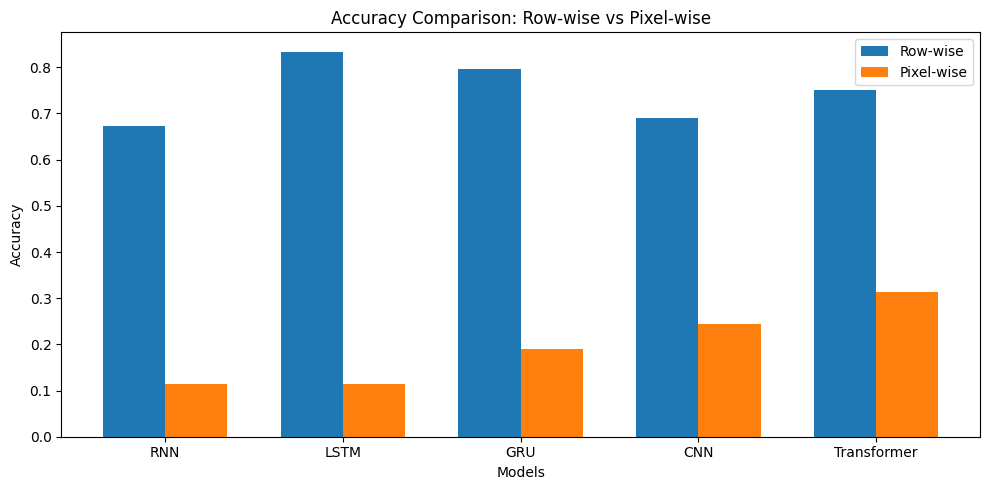

In [15]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    [row_results[name]["Accuracy"] for name in model_names],
    width,
    label="Row-wise"
)

plt.bar(
    x + width / 2,
    [pixel_results[name]["Accuracy"] for name in model_names],
    width,
    label="Pixel-wise"
)

plt.xticks(x, model_names)
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison: Row-wise vs Pixel-wise")
plt.legend()
plt.tight_layout()
plt.show()

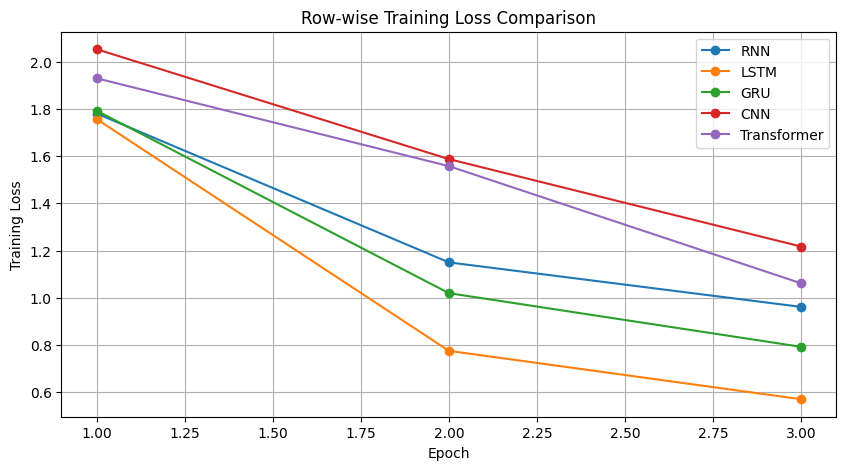

In [16]:
plt.figure(figsize=(10, 5))

for name in model_names:

    plt.plot(
        range(1, len(row_results[name]["Loss History"]) + 1),
        row_results[name]["Loss History"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Row-wise Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

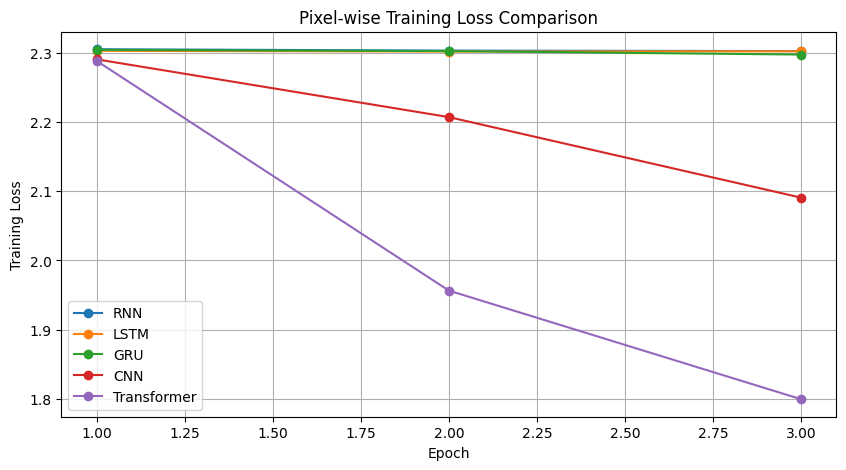

In [17]:
plt.figure(figsize=(10, 5))

for name in model_names:

    plt.plot(
        range(1, len(pixel_results[name]["Loss History"]) + 1),
        pixel_results[name]["Loss History"],
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Pixel-wise Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
comparison_df.to_csv(
    "MNIST_Final_Comparison.csv",
    index=False
)

parameter_df.to_csv(
    "MNIST_Parameter_Comparison.csv",
    index=False
)

print(" comparison files saved successfully.")

 comparison files saved successfully.


1. MNIST images were converted into row-wise and pixel-wise sequences.
2. Row-wise representation contains 28 time steps and 28 features.
3. Pixel-wise representation contains 784 time steps and one feature.
4. Five models were implemented: RNN, LSTM, GRU, CNN, and Transformer.
5. In the row-wise experiment, LSTM achieved the highest accuracy of 83.4%.
6. In the pixel-wise experiment, Transformer achieved the highest accuracy of 31.4%.
7. Pixel-wise training required considerably more time for the recurrent models and Transformer.
8. The model performance changed depending on the sequence representation.


Task 13: Investigate Vanishing Gradients

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [20]:
np.random.seed(42)
torch.manual_seed(42)

# Dataset settings
num_samples = 2000
sequence_length = 100
num_features = 1

# Generate random sequences
X = np.random.randn(
    num_samples, sequence_length, num_features
).astype(np.float32)

# Target depends on the first time step
y = (X[:, 0, 0] > 0).astype(np.float32)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Class distribution:", np.unique(y, return_counts=True))

Input shape: (2000, 100, 1)
Target shape: (2000,)
Class distribution: (array([0., 1.], dtype=float32), array([ 981, 1019]))


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

# Create DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1600
Testing samples: 400


In [22]:
class GradientModel(nn.Module):

    def __init__(self, model_type, input_size=1, hidden_size=32):
        super().__init__()

        self.model_type = model_type

        if model_type == "RNN":
            self.rnn = nn.RNN(
                input_size,
                hidden_size,
                batch_first=True,
                nonlinearity="tanh"
            )

        elif model_type == "LSTM":
            self.rnn = nn.LSTM(
                input_size,
                hidden_size,
                batch_first=True
            )

        elif model_type == "GRU":
            self.rnn = nn.GRU(
                input_size,
                hidden_size,
                batch_first=True
            )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):

        output = self.rnn(x)

        if self.model_type == "LSTM":
            hidden_state = output[1][0][-1]

        elif self.model_type == "GRU":
            hidden_state = output[1][-1]

        else:
            hidden_state = output[1][-1]

        prediction = self.fc(hidden_state)

        return prediction

In [23]:
def train_model(model, train_loader, epochs=15):

    model = model.to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    epoch_losses = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)
        epoch_losses.append(average_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {average_loss:.4f}"
        )

    return model, epoch_losses

In [24]:
model_types = ["RNN", "LSTM", "GRU"]

trained_models = {}
training_histories = {}

for model_type in model_types:

    print("\nTraining", model_type)

    model = GradientModel(model_type)

    trained_model, losses = train_model(
        model,
        train_loader,
        epochs=15
    )

    trained_models[model_type] = trained_model
    training_histories[model_type] = losses


Training RNN
Epoch [1/15], Loss: 0.6941
Epoch [2/15], Loss: 0.6937
Epoch [3/15], Loss: 0.6932
Epoch [4/15], Loss: 0.6928
Epoch [5/15], Loss: 0.6925
Epoch [6/15], Loss: 0.6929
Epoch [7/15], Loss: 0.6927
Epoch [8/15], Loss: 0.6925
Epoch [9/15], Loss: 0.6925
Epoch [10/15], Loss: 0.6921
Epoch [11/15], Loss: 0.6923
Epoch [12/15], Loss: 0.6926
Epoch [13/15], Loss: 0.6925
Epoch [14/15], Loss: 0.6924
Epoch [15/15], Loss: 0.6923

Training LSTM
Epoch [1/15], Loss: 0.6933
Epoch [2/15], Loss: 0.6931
Epoch [3/15], Loss: 0.6932
Epoch [4/15], Loss: 0.6929
Epoch [5/15], Loss: 0.6930
Epoch [6/15], Loss: 0.6931
Epoch [7/15], Loss: 0.6929
Epoch [8/15], Loss: 0.6929
Epoch [9/15], Loss: 0.6929
Epoch [10/15], Loss: 0.6931
Epoch [11/15], Loss: 0.6928
Epoch [12/15], Loss: 0.6928
Epoch [13/15], Loss: 0.6928
Epoch [14/15], Loss: 0.6930
Epoch [15/15], Loss: 0.6927

Training GRU
Epoch [1/15], Loss: 0.6933
Epoch [2/15], Loss: 0.6931
Epoch [3/15], Loss: 0.6930
Epoch [4/15], Loss: 0.6929
Epoch [5/15], Loss: 0.6929


In [25]:
def evaluate_model(model, test_loader):

    model.eval()

    actual_values = []
    predicted_values = []

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            batch_X = batch_X.to(device)

            outputs = model(batch_X)

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= 0.5).float()

            actual_values.extend(batch_y.numpy().flatten())
            predicted_values.extend(
                predictions.cpu().numpy().flatten()
            )

    accuracy = accuracy_score(
        actual_values,
        predicted_values
    )

    return accuracy


accuracy_results = {}

for model_type, model in trained_models.items():

    accuracy = evaluate_model(model, test_loader)

    accuracy_results[model_type] = accuracy

    print(f"{model_type} Accuracy: {accuracy:.4f}")

RNN Accuracy: 0.4925
LSTM Accuracy: 0.4950
GRU Accuracy: 0.4900


In [26]:
def measure_gradients(model, test_loader):

    model.eval()

    gradient_sum = torch.zeros(sequence_length)
    total_samples = 0

    criterion = nn.BCEWithLogitsLoss()

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Enable gradient calculation for input
        batch_X.requires_grad_(True)

        outputs = model(batch_X)

        loss = criterion(outputs, batch_y)

        model.zero_grad()
        loss.backward()

        # Average absolute gradient for each time step
        batch_gradients = batch_X.grad.abs().mean(dim=(0, 2))

        gradient_sum += batch_gradients.detach().cpu() * batch_X.size(0)

        total_samples += batch_X.size(0)

    average_gradients = gradient_sum / total_samples

    return average_gradients.numpy()


gradient_results = {}

for model_type, model in trained_models.items():

    gradients = measure_gradients(model, test_loader)

    gradient_results[model_type] = gradients

    print(
        model_type,
        "Gradient shape:",
        gradients.shape
    )

RNN Gradient shape: (100,)
LSTM Gradient shape: (100,)
GRU Gradient shape: (100,)


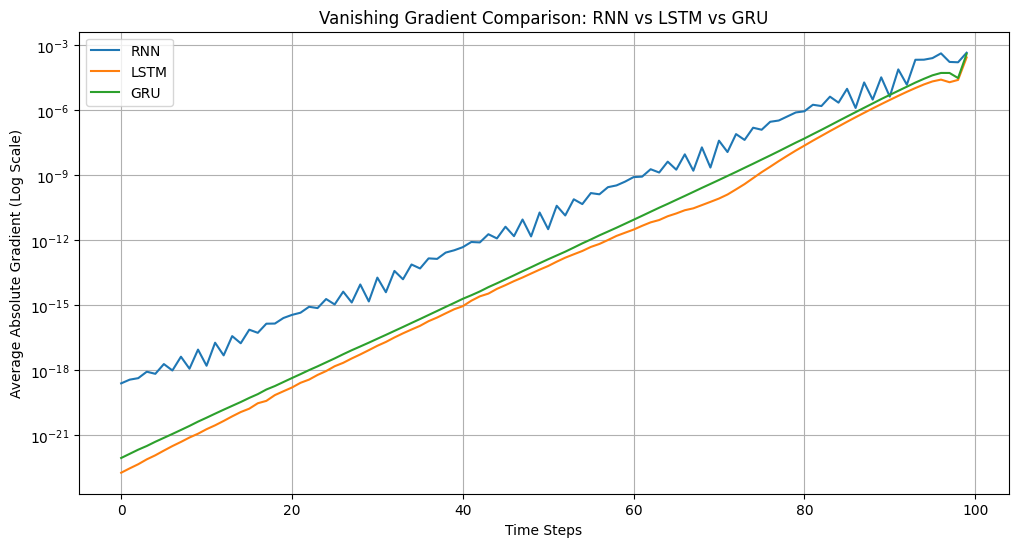

In [27]:
plt.figure(figsize=(12, 6))

for model_type, gradients in gradient_results.items():

    plt.plot(
        range(sequence_length),
        gradients,
        label=model_type
    )

plt.yscale("log")
plt.xlabel("Time Steps")
plt.ylabel("Average Absolute Gradient (Log Scale)")
plt.title("Vanishing Gradient Comparison: RNN vs LSTM vs GRU")
plt.legend()
plt.grid(True)

plt.show()

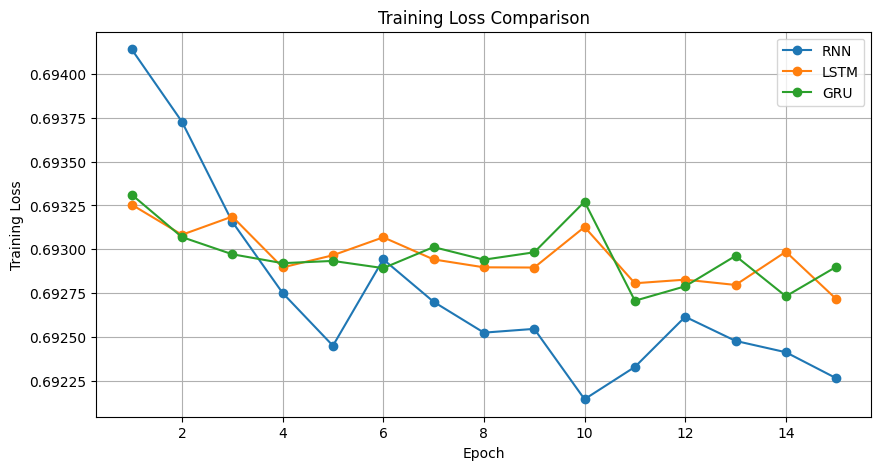

In [28]:
plt.figure(figsize=(10, 5))

for model_type, losses in training_histories.items():

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        marker="o",
        label=model_type
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [29]:
gradient_comparison = pd.DataFrame({
    "Model": list(accuracy_results.keys()),
    "Accuracy": list(accuracy_results.values()),
    "Final Training Loss": [
        training_histories[name][-1]
        for name in accuracy_results.keys()
    ],
    "Average Gradient": [
        gradient_results[name].mean()
        for name in accuracy_results.keys()
    ]
})

display(gradient_comparison.round(6))

,Model,Accuracy,Final Training Loss,Average Gradient
0,RNN,0.4925,0.692266,0.000021
1,LSTM,0.4950,0.692717,0.000004
2,GRU,0.4900,0.692900,0.000007


The vanishing gradient problem occurs when gradients become very small during backpropagation through long sequences.



A basic RNN may struggle to remember information from earlier time steps because gradients can decrease as they pass backward through the sequence.



LSTM uses memory cells and gates to help preserve important information over longer sequences.



GRU uses update and reset gates to control information flow and can also help with long-term dependencies.



Comparing the gradient plots helps us understand how the three architectures respond to information at different time steps.

Task 14 – Gradient Clipping Experiment

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [2]:
np.random.seed(42)
torch.manual_seed(42)

num_samples = 2000
sequence_length = 100
num_features = 1

X = np.random.randn(
    num_samples, sequence_length, num_features
).astype(np.float32)

y = (X[:, 0, 0] > 0).astype(np.float32)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 1600
Testing samples: 400


In [3]:
def calculate_gradient_norm(model):

    total_norm = 0.0

    for parameter in model.parameters():

        if parameter.grad is not None:

            param_norm = parameter.grad.detach().data.norm(2).item()

            total_norm += param_norm ** 2

    total_norm = total_norm ** 0.5

    return total_norm

In [4]:
def train_rnn(model, train_loader, use_clipping, epochs=15):

    model = model.to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_history = []
    gradient_norm_history = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        epoch_gradient_norms = []

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            loss.backward()

            # Measure gradient norm before clipping
            gradient_norm = calculate_gradient_norm(model)

            epoch_gradient_norms.append(gradient_norm)

            # Apply gradient clipping when enabled
            if use_clipping:

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)
        average_gradient_norm = np.mean(epoch_gradient_norms)

        loss_history.append(average_loss)
        gradient_norm_history.append(average_gradient_norm)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {average_loss:.4f} "
            f"Gradient Norm: {average_gradient_norm:.4f}"
        )

    return model, loss_history, gradient_norm_history

In [6]:
import torch
import torch.nn as nn
import copy

class ClippingRNN(nn.Module):

    def __init__(self, input_size=1, hidden_size=32):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
            nonlinearity="tanh"
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):

        output, hidden = self.rnn(x)

        final_hidden = hidden[-1]

        prediction = self.fc(final_hidden)

        return prediction

print("ClippingRNN class defined successfully!")

ClippingRNN class defined successfully!


In [8]:
torch.manual_seed(42)

initial_model = ClippingRNN()

model_without_clipping = copy.deepcopy(initial_model)
model_with_clipping = copy.deepcopy(initial_model)

print("Training without gradient clipping")

model_without_clipping, loss_without, grad_without = train_rnn(
    model_without_clipping,
    train_loader,
    use_clipping=False,
    epochs=15
)

print("\nTraining with gradient clipping")

model_with_clipping, loss_with, grad_with = train_rnn(
    model_with_clipping,
    train_loader,
    use_clipping=True,
    epochs=15
)

Training without gradient clipping
Epoch [1/15] Loss: 0.6941 Gradient Norm: 0.1297
Epoch [2/15] Loss: 0.6937 Gradient Norm: 0.1544
Epoch [3/15] Loss: 0.6932 Gradient Norm: 0.1225
Epoch [4/15] Loss: 0.6928 Gradient Norm: 0.1340
Epoch [5/15] Loss: 0.6925 Gradient Norm: 0.1201
Epoch [6/15] Loss: 0.6929 Gradient Norm: 0.1229
Epoch [7/15] Loss: 0.6927 Gradient Norm: 0.1166
Epoch [8/15] Loss: 0.6925 Gradient Norm: 0.1164
Epoch [9/15] Loss: 0.6925 Gradient Norm: 0.1205
Epoch [10/15] Loss: 0.6921 Gradient Norm: 0.1017
Epoch [11/15] Loss: 0.6923 Gradient Norm: 0.1165
Epoch [12/15] Loss: 0.6926 Gradient Norm: 0.1128
Epoch [13/15] Loss: 0.6925 Gradient Norm: 0.1392
Epoch [14/15] Loss: 0.6924 Gradient Norm: 0.1119
Epoch [15/15] Loss: 0.6923 Gradient Norm: 0.1228

Training with gradient clipping
Epoch [1/15] Loss: 0.6933 Gradient Norm: 0.1151
Epoch [2/15] Loss: 0.6936 Gradient Norm: 0.1184
Epoch [3/15] Loss: 0.6931 Gradient Norm: 0.1276
Epoch [4/15] Loss: 0.6929 Gradient Norm: 0.1188
Epoch [5/15] L

In [9]:
from sklearn.metrics import accuracy_score

def evaluate_rnn(model, test_loader):

    model.eval()

    actual_values = []
    predicted_values = []

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            batch_X = batch_X.to(device)

            outputs = model(batch_X)

            probabilities = torch.sigmoid(outputs)

            predictions = (probabilities >= 0.5).float()

            actual_values.extend(batch_y.numpy().flatten())

            predicted_values.extend(
                predictions.cpu().numpy().flatten()
            )

    return accuracy_score(actual_values, predicted_values)


accuracy_without = evaluate_rnn(
    model_without_clipping,
    test_loader
)

accuracy_with = evaluate_rnn(
    model_with_clipping,
    test_loader
)

print("Accuracy without clipping:", round(accuracy_without, 4))
print("Accuracy with clipping:", round(accuracy_with, 4))

Accuracy without clipping: 0.4925
Accuracy with clipping: 0.5


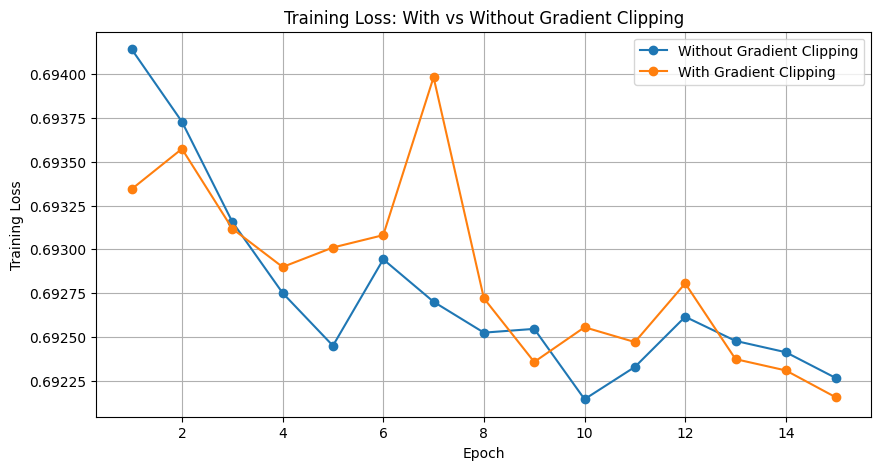

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 16),
    loss_without,
    marker="o",
    label="Without Gradient Clipping"
)

plt.plot(
    range(1, 16),
    loss_with,
    marker="o",
    label="With Gradient Clipping"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss: With vs Without Gradient Clipping")
plt.legend()
plt.grid(True)

plt.show()

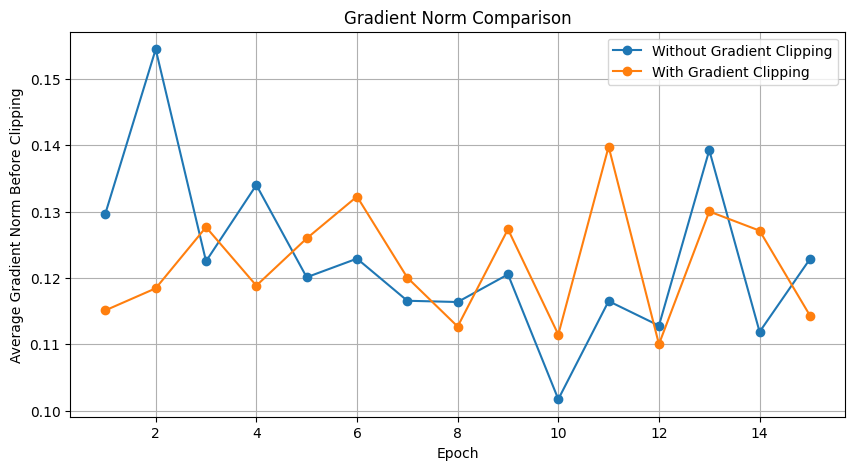

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 16),
    grad_without,
    marker="o",
    label="Without Gradient Clipping"
)

plt.plot(
    range(1, 16),
    grad_with,
    marker="o",
    label="With Gradient Clipping"
)

plt.xlabel("Epoch")
plt.ylabel("Average Gradient Norm Before Clipping")
plt.title("Gradient Norm Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
gradient_clipping_results = pd.DataFrame({
    "Training Method": [
        "Without Gradient Clipping",
        "With Gradient Clipping"
    ],
    "Accuracy": [
        accuracy_without,
        accuracy_with
    ],
    "Final Training Loss": [
        loss_without[-1],
        loss_with[-1]
    ],
    "Average Gradient Norm": [
        np.mean(grad_without),
        np.mean(grad_with)
    ]
})

display(gradient_clipping_results.round(4))

,Training Method,Accuracy,Final Training Loss,Average Gradient Norm
0,Without Gradient Clipping,0.4925,0.6923,0.1228
1,With Gradient Clipping,0.5000,0.6922,0.1221


Gradient clipping limits the gradient norm during backpropagation.



Without clipping, large gradients can cause unstable model updates and lead to the exploding gradient problem.



With clipping, gradients are restricted to the specified maximum norm of 1.0.



Gradient clipping can make training more stable when very large gradients occur.



The accuracy and training loss help us compare the performance of both approaches.

## Task 15: Final Comparison Report

In this assignment, I explored different Recurrent Neural Network architectures and studied how they handle sequential data.

The experiments included comparing RNN, LSTM, and GRU, understanding the vanishing gradient problem, and examining how gradient clipping helps control exploding gradients.

The main objective was to understand the strengths and limitations of each architecture.



| Model | Accuracy | Parameters | Training Time | Long-Term Memory |
|---|---|---|---|---|
| RNN | Row-wise: 67.2%, Pixel-wise: 11.5% | Row-wise: 6,666, Pixel-wise: 4,938 | Row-wise: 3.02 sec, Pixel-wise: 91.67 sec | Short-term memory |
| LSTM | Row-wise: 83.4%, Pixel-wise: 11.5% | Row-wise: 24,714, Pixel-wise: 17,802 | Row-wise: 6.83 sec, Pixel-wise: 478.84 sec | Very good |
| GRU | Row-wise: 79.7%, Pixel-wise: 19.1% | Row-wise: 18,698, Pixel-wise: 13,514 | Row-wise: 13.76 sec, Pixel-wise: 365.76 sec | Good |
| 1D CNN | Row-wise: 69.0%, Pixel-wise: 24.4% | Row-wise: 9,578, Pixel-wise: 6,986 | Row-wise: 2.00 sec, Pixel-wise: 14.72 sec | No explicit recurrent memory |

In [18]:
trained_models = {}
training_histories = {}
comparison_results = []

In [20]:
import torch
import torch.nn as nn

class MNISTModel(nn.Module):

    def __init__(self, model_type, input_size):

        super(MNISTModel, self).__init__()

        self.model_type = model_type
        hidden_size = 64

        # Vanilla RNN
        if model_type == "RNN":

            self.network = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )

            self.fc = nn.Linear(hidden_size, 10)

        # LSTM
        elif model_type == "LSTM":

            self.network = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )

            self.fc = nn.Linear(hidden_size, 10)

        # GRU
        elif model_type == "GRU":

            self.network = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )

            self.fc = nn.Linear(hidden_size, 10)

        # 1D CNN
        elif model_type == "CNN":

            self.network = nn.Sequential(

                nn.Conv1d(
                    input_size, 64,
                    kernel_size=3,
                    padding=1
                ),

                nn.ReLU(),

                nn.MaxPool1d(2),

                nn.Conv1d(
                    64, 128,
                    kernel_size=3,
                    padding=1
                ),

                nn.ReLU(),

                nn.AdaptiveAvgPool1d(1),

                nn.Flatten()
            )

            self.fc = nn.Linear(128, 10)

        # Transformer
        elif model_type == "Transformer":

            self.embedding = nn.Linear(
                input_size, hidden_size
            )

            self.position = nn.Parameter(
                torch.randn(1, 784, hidden_size) * 0.02
            )

            encoder_layer = nn.TransformerEncoderLayer(
                d_model=hidden_size,
                nhead=4,
                dim_feedforward=128,
                batch_first=True
            )

            self.network = nn.TransformerEncoder(
                encoder_layer,
                num_layers=2
            )

            self.fc = nn.Linear(hidden_size, 10)

        else:

            raise ValueError("Invalid model type")

    def forward(self, x):

        if self.model_type in ["RNN", "LSTM", "GRU"]:

            output, hidden = self.network(x)

            if self.model_type == "LSTM":
                hidden = hidden[0]

            features = hidden[-1]

        elif self.model_type == "CNN":

            x = x.transpose(1, 2)

            features = self.network(x)

        elif self.model_type == "Transformer":

            x = self.embedding(x)

            x = x + self.position[:, :x.size(1), :]

            output = self.network(x)

            features = output.mean(dim=1)

        return self.fc(features)

In [21]:
model = MNISTModel(
    model_type="RNN",
    input_size=28
)

sample = torch.randn(4, 28, 28)

output = model(sample)

print("Output shape:", output.shape)

Output shape: torch.Size([4, 10])


In [15]:
clipping_comparison = pd.DataFrame({
    "Model": ["Without Gradient Clipping", "With Gradient Clipping"],
    "Final Training Loss": [loss_without[-1], loss_with[-1]],
    "Test Accuracy": [
        calculate_accuracy(model_without_clipping, test_loader),
        calculate_accuracy(model_with_clipping, test_loader)
    ],
    "Maximum Gradient Norm": [
        max(grad_without),
        max(grad_with)
    ]
})

display(clipping_comparison)

,Model,Final Training Loss,Test Accuracy,Maximum Gradient Norm
0,Without Gradient Clipping,0.692266,0.4925,0.154447
1,With Gradient Clipping,0.692156,0.5000,0.139773


## Observations

1. Simple RNNs can have difficulty learning information from earlier time steps because of the vanishing gradient problem.

2. LSTM uses gates to control information flow and helps preserve long-term information.

3. GRU also uses gates and provides a simpler alternative to LSTM.

4. Gradient clipping limits large gradients during training and helps control the exploding gradient problem.

5. The performance of each model depends on the dataset, sequence length, model architecture, and training settings.

## Conclusion

Through these experiments, I understood how recurrent neural networks process sequential information and why different RNN architectures are required.

LSTM and GRU help address the limitations of simple RNNs when learning long-term dependencies. Gradient clipping is also useful for controlling large gradients during model training.

Overall, these experiments helped me understand the practical behaviour of RNN-based models and the importance of selecting a suitable architecture for sequential data.